In [32]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

In [2]:
def tabprint(x):
    return "\t".join(map(str, x))

numb = "57"
tumor = "t"+numb
folder = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"

#infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_good_cells.txt"
#infilename = "/mnt/wigclust23/data/safe/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_with_cluster.txt"
infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_all_cells.txt"

bincounts = pd.read_csv(infilename, sep = "\t")
#table = pd.read_csv(infilename, sep="\t")
cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".not_broken_final_list.txt", header = None)[0].values
#counts = np.array(table)[:,3:]

In [3]:
table = bincounts[list(bincounts.columns[:5])+list(cells)]

In [4]:
break_points = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/enca"+numb+"_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")

In [5]:
break_points = break_points[break_points["chrom"]!="chrY"]

In [6]:
break_points.head()

,ID,chrom,loc.start,loc.end,num.mark,seg.mean
0,enca57_1M,chr1,0,45387037,78,-0.1896
1,enca57_1M,chr1,45972336,119478274,132,0.5035
2,enca57_1M,chr1,120035598,175362842,52,0.7333
3,enca57_1M,chr1,175900450,182029442,12,0.3150
4,enca57_1M,chr1,182578512,248389233,118,-0.2532


In [7]:
# seurat_clusters = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/seurat_clusters.txt", header = None,sep = "\t")

In [8]:
normal_cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/normal_cells.txt", header = None,sep = "\t")[0].values

In [9]:
normal_cells

array(['AAAACCAACCTGATAAC', 'AAAACCAATTTCAGTAC', 'AAAACCAGTGAGTCTAC', ...,
       'TTTTGGAAGCGTAGACT', 'TTTTGGAGTGAGAGTCG', 'TTTTGGGACCATGTACA'],
      dtype=object)

In [10]:
len(cells), len(normal_cells)

(2533, 1623)

In [11]:
normal_cells = [c for c in cells if c in normal_cells]

In [12]:
len(normal_cells)

1623

In [13]:
table["normal_average"] = table[normal_cells].sum(axis = 1)/len(normal_cells)

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [14]:
table.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,normal_average
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,1193,800,798,1995,971,1103,884,903,1125,971.556993
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,4002,1326,2425,4022,1563,1792,2275,3026,3954,1579.550216
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,3050,879,995,3032,789,896,1354,2382,1533,793.379544
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,384,147,152,384,133,136,159,244,283,133.272335
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,1963,1517,1092,2582,1421,1596,1217,1684,1892,1393.640789


In [15]:
data = table[["chrom","abstart", "abend", "normal_average"]].copy()
q_table = table[["chrom","abstart", "abend", "normal_average"]].copy()

In [16]:
totlen = sum(table["normal_average"])

In [17]:
for n in cells:
    
    q_table[n] = table[n]/sum(table[n])
    q_table[n] = (totlen*q_table[n])/(table["normal_average"])
    data[n] = table[n]

In [18]:
def calc_single(not_normal,q_not_normal):
    obs_NV = np.array(not_normal)[:,:].T
    single = q_not_normal.mean(axis = 1).values
    logmult_KV   = np.log(np.concatenate([[single],[single]]))
    #logmixprob_K = np.log(mixprob_K)
    ## multinomial probability is a dot product in log space
    ## that's cool. 
    logprob_single_NK = np.dot(obs_NV, logmult_KV.T)
    logsum_N   = [logsumexp(list(x)) for x in logprob_single_NK]

    single_lik = sum(logsum_N)
    
    return single_lik

In [60]:
def make_seeds(q_not_normal):
    Seeds = []
    for i in range(len(q_not_normal)):
        #print(i)
        s = []
        #l1 = q_not_normal.loc[i].values
        for j in range(len(q_not_normal)):
            l2 = q_not_normal.loc[j].values
            mi, m, mx = min(l2), l2.mean(), max(l2)
            if i==j:
                s.append([(mi+m)/2, (mx+m)/2])
            else:
                s.append([m, m])
        Seeds.append(s)
    return Seeds

In [91]:
def single_random_seed(q_not_normal):
    s = []
        
    for j in range(len(q_not_normal)):
        l2 = q_not_normal.loc[j].values
        mi, mx = min(l2), max(l2)
        s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
    return s

In [53]:
def make_random_seeds(q_not_normal):
    Seeds = []
    for i in range(len(q_not_normal)):
        #print(i)
        s = []
        #l1 = q_not_normal.loc[i].values
        for j in range(len(q_not_normal)):
            l2 = q_not_normal.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds

In [49]:
def EM_algorithm(data,s, MIN_DIFF  = 0.001):
    
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.Inf
    ## initialize log prob matrix, will be reused for speed.
    #logprob_NK = np.zeros(shape=(N,K))
    ## initialize multinomial emissions probabilities
    ## here, at random
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    #print(mult_KV)
    for i in range(20):
        logmult_KV = np.log(mult_KV)
        #print(logmult_KV)
        #logmixprob_K = np.log(mixprob_K)
        ## multinomial probability is a dot product in log space
        ## that's cool.
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        #print(logprob_NK)
        logsum_N   = [logsumexp(list(x)) for x in logprob_NK]
        ## by the by, the total of the logsumN is ~ to the the log likelihood.
        ## in effect, what we are trying to maximize.
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])
        #print(logprob_NK)

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        #sum_K = np.sum(mult_KV, axis=1)
        #mult_KV = mult_KV / sum_K[:, np.newaxis]
        ## set a lowest possible multinomial value, and renorm
        #mult_KV = np.maximum(mult_KV, MINPROB)
        #sum_K   = np.sum(mult_KV, axis=1)
        log_diff = abs(log_likelihood-log_likelihood_last)
        #print (log_likelihood-log_likelihood_last )
        if log_diff < MIN_DIFF:
            #print ( 'enough already...' )
            break
    if log_diff > 10*MIN_DIFF:
        return logprob_NK, -np.Inf
    
    return logprob_NK, log_likelihood

In [61]:
def alg_on_seeds(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    Seeds = make_seeds(q_data)
    
    for s in Seeds:
        logprob_NK, log_lik = EM_algorithm(data,s)
        output = dict(zip(data.columns, logprob_NK))
        poss_outputs.append(logprob_NK)
        lik.append(log_lik)
#         H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
#         plt.show()
    
    return poss_outputs, lik

In [54]:
def alg_on_random_seed(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    Seeds = make_random_seeds(q_data)
    
    for s in Seeds:
        logprob_NK, log_lik = EM_algorithm(data,s)
        output = dict(zip(data.columns, logprob_NK))
        poss_outputs.append(logprob_NK)
        lik.append(log_lik)
#         H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
#         plt.show()
    
    return poss_outputs, lik

In [92]:
def alg_on_single_seed(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    s = single_random_seed(q_data)
    
    
    logprob_NK, log_lik = EM_algorithm(data,s)
    
    return logprob_NK, log_lik

In [37]:
all_data = data[cells]

In [38]:
q_all_data = (all_data/all_data.sum(axis=0))

In [39]:
q_data = pd.DataFrame()
for name in q_all_data.columns:
    q_data[name] = q_all_data[name]/(data["normal_average"])

In [55]:
poss_outputs, lik = alg_on_random_seed(all_data)

In [62]:
poss_outputs1, lik1 = alg_on_seeds(all_data)

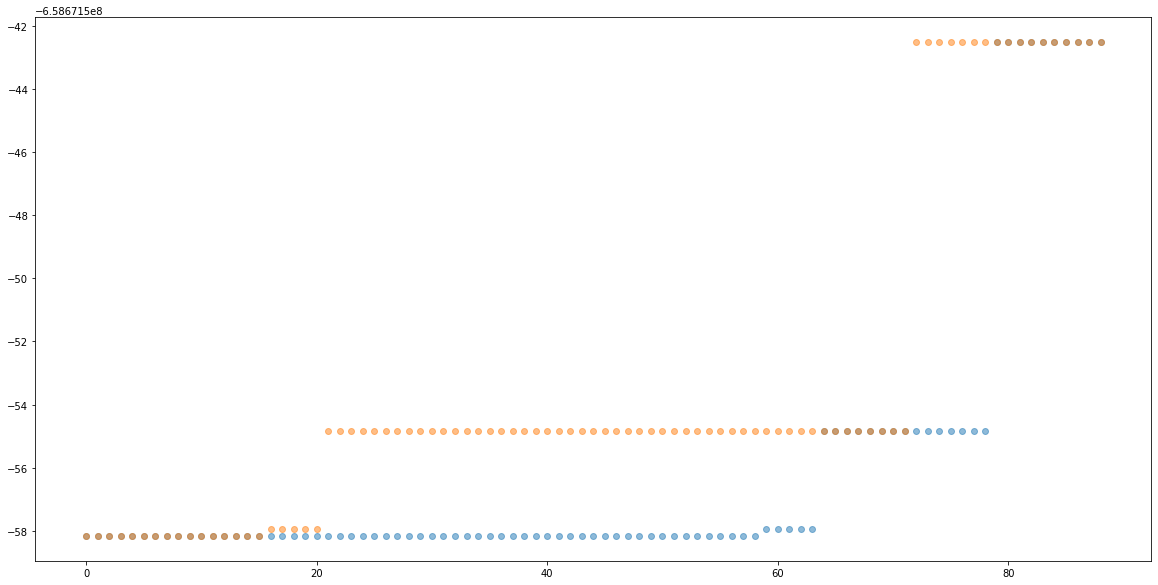

In [65]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.scatter(range(len(lik)),sorted(lik), alpha = 0.5)
plt.scatter(range(len(lik1)),sorted(lik1), alpha = 0.5)
#plt.axhline(single_lik)

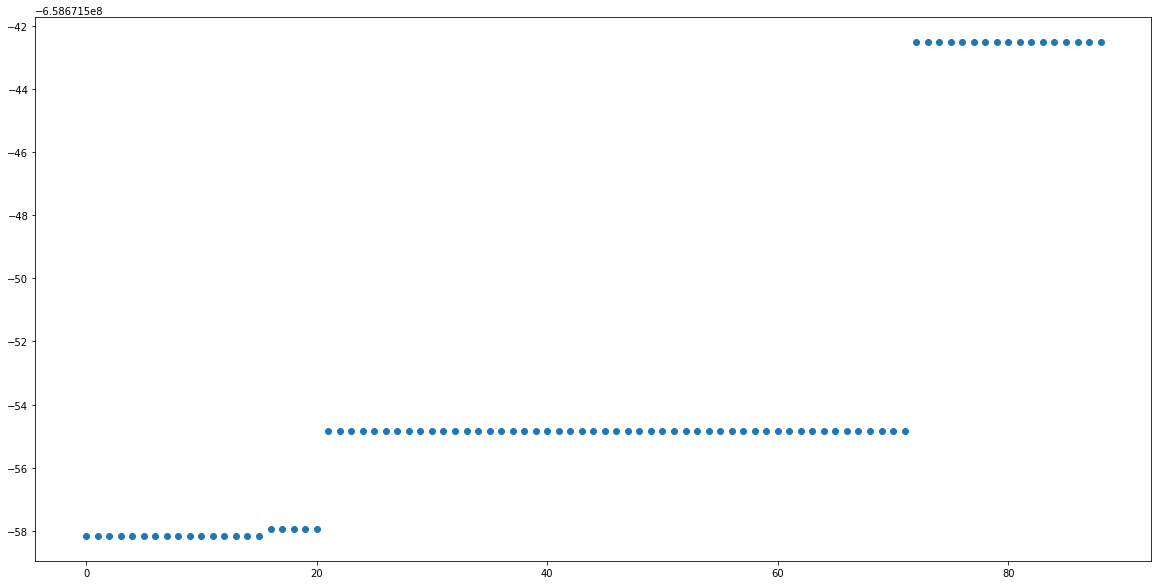

In [26]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.scatter(range(len(lik)),sorted(lik))
#plt.axhline(single_lik)

In [27]:
logprob_NK = poss_outputs[np.argmax(lik)]
cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

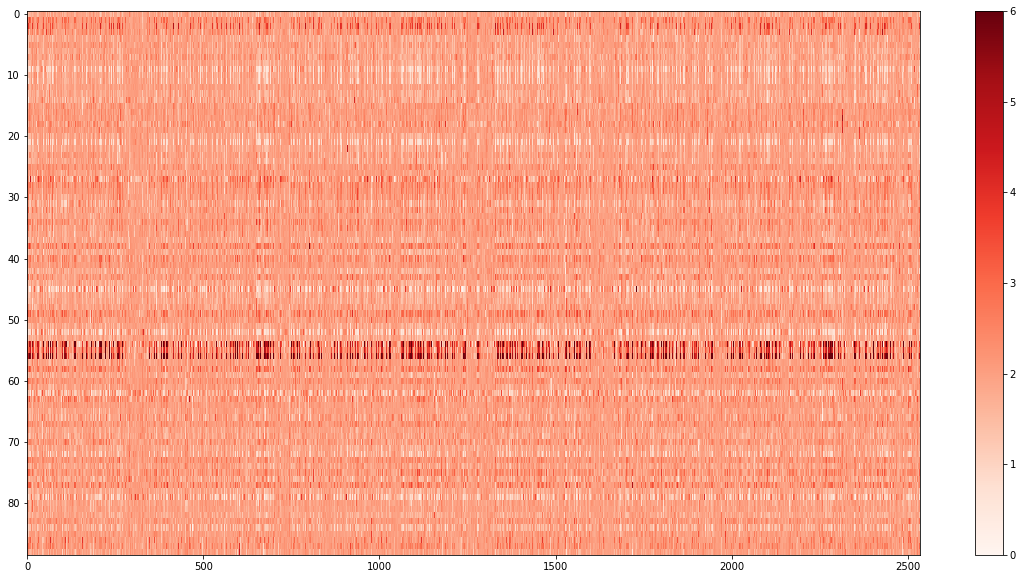

In [28]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values), cmap = 'Reds',interpolation='nearest', aspect='auto', vmin=0, vmax=6)
fig.colorbar(h)

In [29]:
logprob_NK = poss_outputs[np.argmax(lik)]

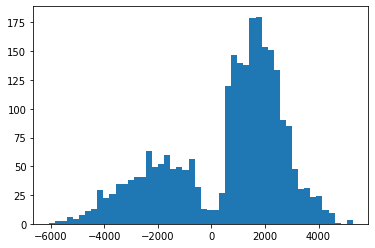

In [30]:
H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
plt.show()

In [31]:
logprob_NK = poss_outputs[np.argmax(lik)]
cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

In [ ]:
len(cluster1), len(cluster2)

In [66]:
sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
new_sub = all_data[[all_data.columns[i] for i in cluster1]]

In [67]:
poss_outputs_new, lik_new = alg_on_seeds(new_sub)

In [68]:
logprob_NK = poss_outputs_new[np.argmax(lik_new)]



In [ ]:
# def Algorithm(all_data, count = 0, cut_off = 5000):
#     output = []
#     q_all_data = (all_data/all_data.sum(axis=0))
    
#     global new_order
#     new_order = [i for i in range(len(all_data.columns))]
    
#     global vlines
    
#     vlines = []
    
#     def binary_tree(all_data, q_all_data, before =[] , order = new_order, after=[],count = 0):
#         #print("instance")
        
#         global new_order
#         global vlines
        
#         if len(all_data.columns)<100:
#             return
        
#         poss_outputs, lik = alg_on_seeds(all_data)
        
#         logprob_NK = poss_outputs[np.argmax(lik)]
#         cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#         cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
        
#         if len(cluster1)<50:
#             return
#         if len(cluster2)<50:
#             return
        
#         single_lik = calc_single(all_data, q_all_data)
        
#         if (max(lik)-single_lik)<=cut_off:
#             return
            
#         output.append([count,[all_data.columns[i] for i in cluster1], [all_data.columns[i] for i in cluster2],(max(lik)-single_lik)])        
        
#         sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
#         new_sub = all_data[[all_data.columns[i] for i in cluster1]]
        
#         order1 = [order[i] for i in cluster1]
#         order2 = [order[i] for i in cluster2]
        
        
#         print(before)
        
#         new_order = before+order1+order2+after
        
#         vlines.append([count, len(before+order1)])
#         count = count+1
        
#         binary_tree(new_sub, sub_q, before,order1, order2+after ,count)
        
#         sub_q = q_all_data[[q_all_data.columns[i] for i in cluster2]]
#         new_sub = all_data[[all_data.columns[i] for i in cluster2]]
        
#         binary_tree(new_sub, sub_q, new_order[:len(before+order1)],order2, after, count)
#         return
    
#     binary_tree(all_data, q_all_data, count = 0)
    
#     return output, new_order, vlines

In [ ]:
#output, new_order, vlines = Algorithm(all_data)

In [ ]:
# output_cell_list = [all_data.columns[i] for i in new_order]
# q_data = q_data[output_cell_list]

In [ ]:
# fig,ax = plt.subplots(1,figsize=(20, 10))
# h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values), cmap = 'Reds',interpolation='nearest', aspect='auto', vmin=0, vmax=5)
# fig.colorbar(h)
# L = 1/len(vlines)
# lines = [l[1] for l in vlines]
# for l in vlines:
#     print(1 - l[0]*L)
#     plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)

In [ ]:
# clusters = []
# current = 0
# for l in sorted(lines):
#     cl = []
#     for i in new_order[current:l]:
#         cl.append(all_data.columns[i])
#     clusters.append(cl)
#     current = l
# cl = []
# for i in new_order[current:]:
#     cl.append(all_data.columns[i])
# clusters.append(cl)

In [ ]:
#names_list = [name for name in seurat_clusters[1].unique() if name!="broken."+tumor+".txt"]

In [ ]:
# bar_lists = []
# for cl in clusters:
#     B = []
#     for name in names_list:
#         G = seurat_G.get_group(name)
#         n = len([name for name in G[0].values if name in cl])
#         B.append(n)
#     bar_lists.append(np.array(B))

In [ ]:
# prev = np.zeros(len(names_list))
# fig,ax = plt.subplots(1, figsize=(20, 10))
# for B in bar_lists:
#     plt.bar(names_list, B, bottom = prev)
#     prev = prev+B

In [69]:
def int_diff(R,X0, X1):
    
    diff = lambda y : (y-round(y))**2
    out = 0
    
    for i in range(len(R)):
#         locs = loc_list[(loc_list["equi_bin"]<X[i+1]) & (loc_list["equi_bin"]>=X[i])]
#         out = out+diff(Y[i])*(len(locs))
        out = out + diff(R[i])*(X1[i]-X0[i])
    
    return out


def ploidy(R,X0,X1,m_range = [1.5,5.5]):
    mul = np.linspace(m_range[0],m_range[1],101)
    diff_list = []
    
    for m in mul:
        diff_list.append(int_diff(m*R,X0, X1))
    
    #a = np.argmin(diff_list)
    #plt.plot(mul,diff_list)
    return mul, diff_list

def ploidy_list(out):
    A = np.array(out[1])
    B = A[1:]-A[:-1]
    B0 = B[:-1]
    B1 = B[1:]
    I = np.where((B0<0) & (B1>0))[0] 
    return sorted(dict(zip([out[0][i+1] for i in I],[out[1][i+1] for i in I])).items(), key=lambda item: item[0])

    

In [70]:
cells

array(['AAAACCAACCTGATAAC', 'AAAACCAACTTTTGACG', 'AAAACCAATTTCAGTAC', ...,
       'TTTTGGGACGAAGTAGC', 'TTTTGGGTGCAATGTCC', 'TTTTGGTATTCTAGTAC'],
      dtype=object)

In [71]:
# def balanced_ploidy(cl):
#     balance_array = []
#     col = data[cl].sum(axis = 1)
#     normal_factor = data["normal_average"].values
#     Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
#     for s in range(len(Z)):
#         hap = hap_grps.get_group(s)
#         sub_hap = hap[hap["cell"].isin(cl)]
#         hap_fractions_min = []
#         bin_list = sorted(sub_hap["bin"].unique())
#         for b in bin_list:
#             bin_info = sub_hap[sub_hap["bin"]==b]
#             h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#             hap_fractions_min.append(min(h, 1-h))
#         al = sum(hap_fractions_min)/len(hap_fractions_min)
#         balance_array.append(int((al>0.4)))

    
#     #print(Z)
#     out = ploidy(Z,X,Y)
#     #print(out)
#     all_pl = ploidy_list(out)
#     print(all_pl)
    
#     balance_pl = []
    
#     for p in all_pl:
#         pl = p[0]
#         b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
#         balance_pl.append(1-b)
#         #print(pl, b)
        
    
# #     best_pl = all_pl[np.argmax(balance_pl)][0]
#     print(balance_pl)
#     print(np.argsort(balance_pl))
#     for ind in np.argsort(balance_pl):
#         best_pl = all_pl[ind][0]
#         if sum([round(z)==0 for z in Z*best_pl])==0:
#             break
#         else:
#             print(Z*best_pl)

#     return best_pl

In [72]:
def binary_search(a, L, start, end):
    if start==end:
        return start
    if a<=L[0]:
        return 0
    if a>=L[-1]:
        return len(L)-1
    mid = (end+start)//2
    
    if (a<L[mid]) and (a>=L[mid-1]):
        return mid
    elif a>=L[mid]:
        return binary_search(a, L, mid, end)
    else:
        return binary_search(a, L, start, mid)

In [73]:
hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count.txt", sep = "\t")
hap_count_df.head()
# bin_list = sorted(hap_count_df["bin"].unique())
# hap_type = dict()
# bin_list = sorted(hap_count_df["bin"].unique())
# for b in bin_list:
#     #print(b)
#     bin_info = hap_count_df[hap_count_df["bin"]==b]
#     h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#     hap_type[b] = int(h>=0.5)
# hap_grps = hap_count_df.groupby("seg")

,Total,hap_count,cell,bin
0,6,3,AATGAGGATGCAACACA,0
1,2,0,AATGAGGATGCAACACA,1
2,2,0,AATGAGGATGCAACACA,2
3,7,7,AATGAGGATGCAACACA,3
4,0,0,AATGAGGATGCAACACA,4


In [74]:
binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])

In [75]:
data.head()

,chrom,abstart,abend,normal_average,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,...,TTTTGGAAGCGTAGACT,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC
0,chr1,0,45387037,971.556993,570,1604,403,1325,853,310,...,1160,1193,800,798,1995,971,1103,884,903,1125
1,chr1,45972336,119478274,1579.550216,928,5401,596,4437,2675,449,...,2108,4002,1326,2425,4022,1563,1792,2275,3026,3954
2,chr1,120035598,175362842,793.379544,506,2172,294,1671,1987,253,...,1030,3050,879,995,3032,789,896,1354,2382,1533
3,chr1,175900450,182029442,133.272335,83,230,66,184,232,53,...,153,384,147,152,384,133,136,159,244,283
4,chr1,182578512,248389233,1393.640789,819,2760,612,1954,1335,462,...,1759,1963,1517,1092,2582,1421,1596,1217,1684,1892


In [76]:
position_list = hap_count_df["abspos"].unique()
locations = bincounts["abend"].values
pos_seg = []
for p in position_list:
    pos_seg.append(binary_search(p,locations, 0, len(locations)))

In [77]:
pos_seg_dict = dict(zip(position_list, pos_seg))

In [78]:
hap_count_df["seg"] = hap_count_df["abspos"].apply(lambda x : pos_seg_dict[x])

In [79]:
#hap_count_df.to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count_WGS_seg.txt", sep = "\t", index = None)

In [80]:
bins_df = hap_count_df[["bin", "abspos", "seg"]].copy()
bins_df = bins_df.drop_duplicates()

In [81]:
Normal_df = hap_count_df[hap_count_df["cell"].isin(normal_cells)]

In [82]:
bin_groups = Normal_df.groupby("bin")
binstart = bins_df["bin"].values
ratio = []
for b in binstart:
    df = bin_groups.get_group(b)
    p = df["hap_count"].sum()/df["Total"].sum()
    ratio.append((min(p,1-p)))

(0.0, 3034996761.0)

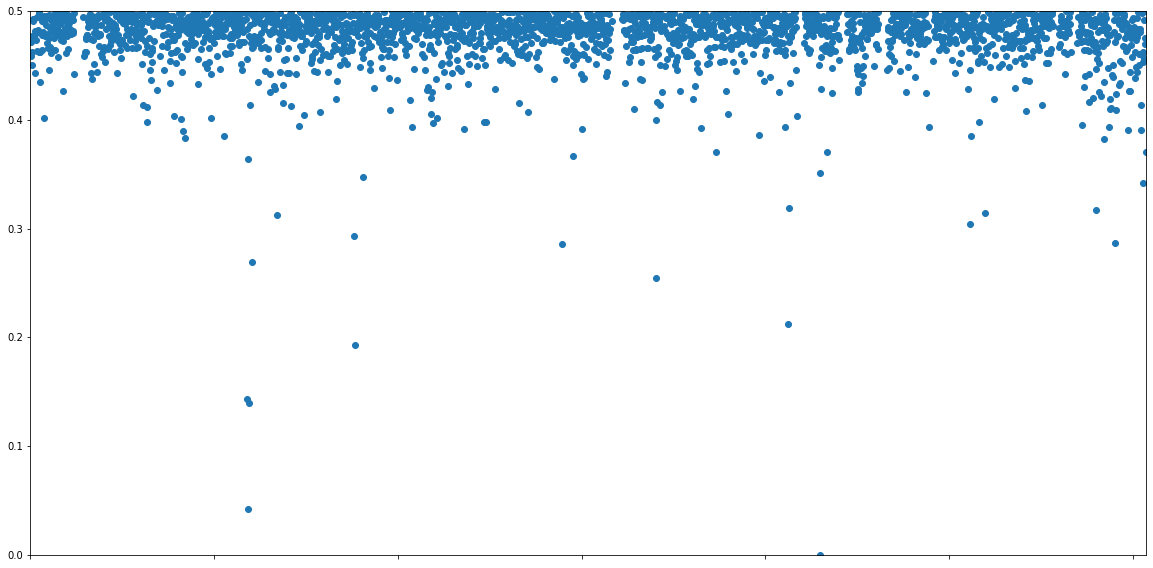

In [83]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.scatter(Normal_df["abspos"].unique(), ratio)
plt.ylim([0, 0.5])
ax.set_xticklabels([]) 
plt.xlim(min(Normal_df["abspos"].unique()), max(Normal_df["abspos"].unique()))

In [84]:
data["cum_length"] = data["normal_average"].cumsum()
X = [0]+list(data["cum_length"].values[:-1])
Y = data["cum_length"].values

In [85]:
def balanced_ploidy(cl):
    T_df = hap_count_df[hap_count_df["cell"].isin(cl)]
    bin_groups = T_df.groupby("bin")
    
    binstart = bins_df["bin"].values
    ratio = []
    for b in binstart:
        df = bin_groups.get_group(b)
        p = df["hap_count"].sum()/df["Total"].sum()
        ratio.append((min(p,1-p)))
    
    bins_df["T_ratio"] = ratio
    
    seg_grps = bins_df.groupby("seg")
    T_al = []
    
    for s in bins_df["seg"].unique():
        segment = seg_grps.get_group(s)
        T_al.append(segment["T_ratio"].mean())
        
    T_al_balance = np.array([int(t>0.4) for t in T_al])
    col = data[cl].sum(axis = 1)
    
    normal_factor = data["normal_average"].values
    totlen = sum(normal_factor)
    
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    out = ploidy(Z,X,Y)
    all_pl = ploidy_list(out)
    fig,ax = plt.subplots(1, figsize=(20, 10))
    plt.plot(out[0], out[1])
    for l in all_pl:
        plt.axvline(l[0], color = "black")
    
    bl_ratio = []
#     print(Z)
#     print(T_al_balance)
    for p in all_pl:
        pl = p[0]
        CN = np.array([int(round(z)%2==0) for z in Z*pl])
        #print([round(z) for z in Z*pl])
        b =  sum((CN*T_al_balance)*normal_factor)/sum(T_al_balance*normal_factor)
        bl_ratio.append(b)
        print(pl, b)
    
    print(" ")
    best_pl = all_pl[np.argmax(bl_ratio)][0]
    
    
    return best_pl

1.98 1.0
2.98 0.0
3.98 1.0
4.98 0.0
 


1.98

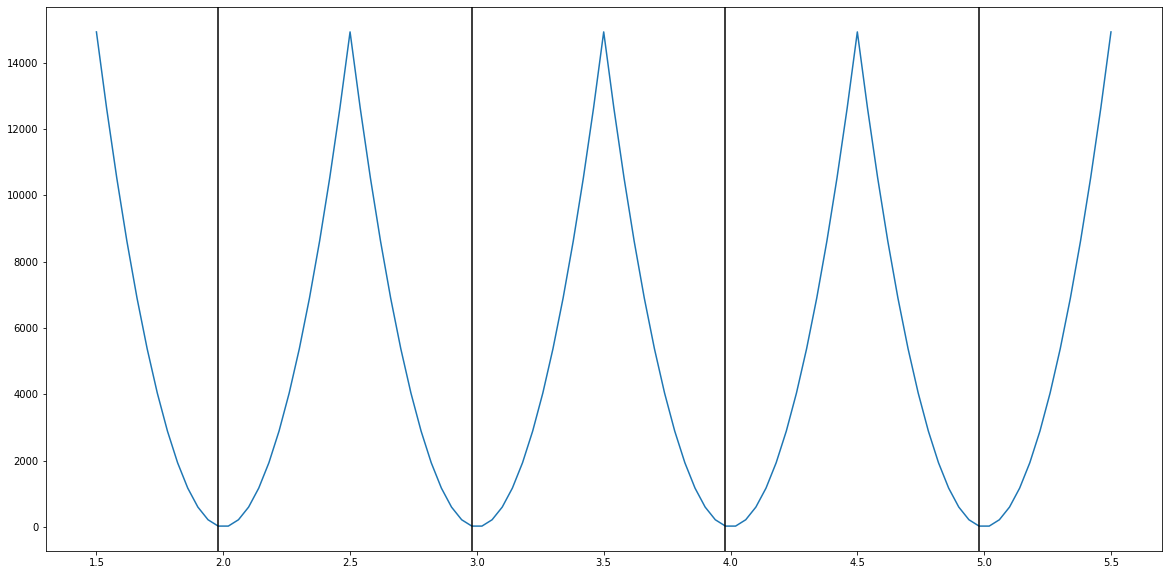

In [86]:
balanced_ploidy(normal_cells)

In [99]:
col = data[normal_cells].sum(axis = 1)

In [100]:
Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
out = ploidy(Z,X,Y)
all_pl = ploidy_list(out)

In [101]:
all_pl


[(1.98, 23.889371041280985),
 (2.98, 23.889371041280985),
 (3.98, 23.88937104128033),
 (4.98, 23.889371041279265)]

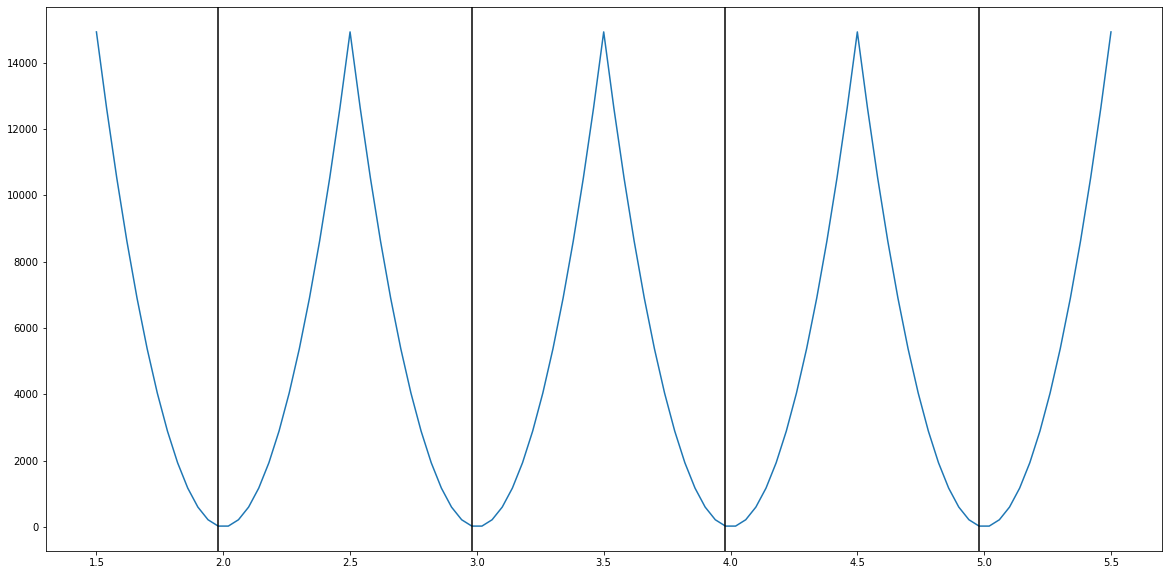

In [102]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.plot(out[0], out[1])
for l in all_pl:
    plt.axvline(l[0], color = "black")

In [107]:
out[0][np.argmin(out[1])]

4.98

In [114]:
def Algorithm_with_ploidy(all_data,normal_average, count = 0, cut_off = 500):
    output = []
    q_all_data = (all_data/all_data.sum(axis=0))
    
    global reg_table
    reg_table = all_data.copy()
    reg_table["length"] = normal_average
    reg_table["cum_length"] = reg_table["length"].cumsum()
    
    global totlen
    totlen = sum(normal_average)
    
    global X
    X = [0]+list(reg_table["cum_length"].values[:-1])
    
    global Y
    Y = reg_table["cum_length"].values
        


    
    
    global new_order
    new_order = [i for i in range(len(all_data.columns))]
    
    global vlines
    vlines = []
    
    global CN_list
    CN_list = []
    
    def binary_tree(all_data, q_all_data, before =[] , order = new_order, after=[],count = 0, before_CN = [], after_CN = []):
        print("instance")
        
        global new_order
        global vlines
        global reg_table
        global totlen
        global X
        global Y
        global CN_list
        
        if len(all_data.columns)<100:
            return
        
        logprob_NK, lik = alg_on_single_seed(all_data)
        
        #cl = all_data.columns
        
        col = all_data.sum(axis = 1)
        
        Z = ((col/sum(col))*totlen)/(reg_table["length"])
        
        reg_table["temp"] = Z

#         out = ploidy(Z,X,Y)
#         all_pl = ploidy_list(out)
        
        #pl = []
        lens = np.array(Y)-np.array(X)
#         for i in range(len(all_pl)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl.append(all_pl[i][0])
        
        
        #pl = sorted(pl)
        
        
        cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
        cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
        
        print("split made")
        
        cl1,cl2 = [all_data.columns[i] for i in cluster1], [all_data.columns[i] for i in cluster2]
        
        if len(cl1)<50:
            return
        if len(cl2)<50:
            return

        col1 = reg_table[cl1].sum(axis = 1)
        col2 = reg_table[cl2].sum(axis = 1)
        
        Z1 = ((col1/sum(col1))*totlen)/(reg_table["length"])
        Z2 = ((col2/sum(col2))*totlen)/(reg_table["length"])
        #print(Z1==Z2)
        
        out1 = ploidy(Z1,X,Y)
        pl1 = out1[0][np.argmin(out1[1])]
        
#        all_pl1 = ploidy_list(out1)

#        pl1 = balanced_ploidy(cl1)
#         pl1 = []
#         for i in range(len(all_pl1)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z1*all_pl1[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl1.append(all_pl1[i][0])
        
        out2 = ploidy(Z2,X,Y)
        pl2 = out2[0][np.argmin(out2[1])]
        
#        all_pl2 = ploidy_list(out2)
#        pl2 = balanced_ploidy(cl2)
#         pl2 = []
#         for i in range(len(all_pl2)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z2*all_pl2[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl2.append(all_pl2[i][0])

        CN1 = (Z1*pl1).apply(lambda x : round(x))==(Z2*pl2).apply(lambda x : round(x))
        #CN2 = (Z1*pl1[1]).apply(lambda x : round(x))==(Z2*pl2[1]).apply(lambda x : round(x))
        
#         cn1 = (Z1*pl1[0]).apply(lambda x : round(x))
#         cn2 = (Z2*pl2[0]).apply(lambda x : round(x))
        cn1 = (Z1*pl1).apply(lambda x : round(x))
        cn2 = (Z2*pl2).apply(lambda x : round(x))
        
        print(sum(lens*CN1)/sum(lens))
              #, sum(lens*CN2)/sum(lens))
        print(len(cluster1), len(cluster2))
              
        if (sum(lens*CN1)/sum(lens)>=1):
              return
              
        if (sum(lens*CN1)/sum(lens)>0.95):
            return
        
#         if (sum(lens*CN1)/sum(lens)>=1) or (sum(lens*CN2)/sum(lens)>=1):
#             return
        
#         if (sum(lens*CN1)/sum(lens)>0.95) or (sum(lens*CN2)/sum(lens)>0.95):
#             return
            
        
        if len(cluster1)<50:
            return
        if len(cluster2)<50:
            return
        
        single_lik = calc_single(all_data, q_all_data)
        
        if (lik-single_lik)<=cut_off:
            return
            
        print("split determined")
        output.append([count,cl1,cl2,(lik-single_lik)])        
        
        sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
        new_sub = all_data[[all_data.columns[i] for i in cluster1]]
        
        order1 = [order[i] for i in cluster1]
        order2 = [order[i] for i in cluster2]
        
        
        #print(before)
        
        new_order = before+order1+order2+after
        CN_list = before_CN + [pl1] + [pl2] + after_CN
        
        vlines.append([count, len(before+order1)])
        count = count+1
        
        binary_tree(new_sub, sub_q, before,order1, order2+after ,count, before_CN, [pl2]+after_CN)
        
        sub_q = q_all_data[[q_all_data.columns[i] for i in cluster2]]
        new_sub = all_data[[all_data.columns[i] for i in cluster2]]
        
        CN_len = len(CN_list)
        after_len = len(after_CN)
        before_len = CN_len - after_len - 1
        
        binary_tree(new_sub, sub_q, new_order[:len(before+order1)],order2, after, count, CN_list[:before_len],after_CN)
        return
    
    binary_tree(all_data, q_all_data, count = 0)
    
    return output, new_order, vlines, CN_list

In [109]:
table.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,normal_average
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,1193,800,798,1995,971,1103,884,903,1125,971.556993
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,4002,1326,2425,4022,1563,1792,2275,3026,3954,1579.550216
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,3050,879,995,3032,789,896,1354,2382,1533,793.379544
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,384,147,152,384,133,136,159,244,283,133.272335
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,1963,1517,1092,2582,1421,1596,1217,1684,1892,1393.640789


In [110]:
normal_average = table["normal_average"].values

In [111]:
all_data

,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,AAAACCGAAATCGGTAT,AAAACCGAACCCGTACA,AAAACCGGACGTATTAA,...,TTTTGGAAGCGTAGACT,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC
0,570,1604,403,1325,853,310,866,479,1113,1009,...,1160,1193,800,798,1995,971,1103,884,903,1125
1,928,5401,596,4437,2675,449,1412,1646,1941,3164,...,2108,4002,1326,2425,4022,1563,1792,2275,3026,3954
2,506,2172,294,1671,1987,253,769,649,974,1250,...,1030,3050,879,995,3032,789,896,1354,2382,1533
3,83,230,66,184,232,53,139,59,162,200,...,153,384,147,152,384,133,136,159,244,283
4,819,2760,612,1954,1335,462,1276,696,1681,1404,...,1759,1963,1517,1092,2582,1421,1596,1217,1684,1892
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,77,203,57,136,97,52,91,60,139,116,...,146,125,121,98,230,123,185,79,137,188
85,284,1063,185,814,340,140,391,258,468,570,...,475,775,365,518,939,413,513,355,656,902
86,770,2422,427,2247,1576,367,1134,935,1401,2336,...,1507,1683,1672,1823,3073,1077,1260,1210,1777,2316
87,419,1614,238,1326,1198,222,615,504,808,1035,...,866,1636,906,815,2043,611,762,861,1475,969


In [112]:
all_data = data[cells]

In [115]:
output, new_order, vlines, CN_list = Algorithm_with_ploidy(all_data, normal_average)

instance
split made
0.014136697869475917
788 1745
split determined
instance
split made
0.5723660397496889
424 364
split determined
instance
split made
0.06724124097891668
125 299
split determined
instance
split made
instance
split made
0.9397677978000935
167 132
instance
split made
0.940017181065776
142 222
split determined
instance
split made
instance
split made
instance
split made
0.9849445776048628
1654 91


In [116]:
CN_list

[3.9, 2.8600000000000003, 2.54, 2.46, 1.98]

In [117]:
#output, new_order, vlines, CN_list = Algorithm_with_ploidy(all_data, normal_average)

In [118]:
output_cell_list = [all_data.columns[i] for i in new_order]
q_data = q_data[output_cell_list]

In [119]:
break_points.head()

,ID,chrom,loc.start,loc.end,num.mark,seg.mean
0,enca57_1M,chr1,0,45387037,78,-0.1896
1,enca57_1M,chr1,45972336,119478274,132,0.5035
2,enca57_1M,chr1,120035598,175362842,52,0.7333
3,enca57_1M,chr1,175900450,182029442,12,0.3150
4,enca57_1M,chr1,182578512,248389233,118,-0.2532


In [120]:
data["len_factor"] = data[normal_cells].sum(axis = 1)/len(normal_cells)

In [121]:
data

,chrom,abstart,abend,normal_average,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,...,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,cum_length,len_factor
0,chr1,0,45387037,971.556993,570,1604,403,1325,853,310,...,800,798,1995,971,1103,884,903,1125,971.556993,971.556993
1,chr1,45972336,119478274,1579.550216,928,5401,596,4437,2675,449,...,1326,2425,4022,1563,1792,2275,3026,3954,2551.107209,1579.550216
2,chr1,120035598,175362842,793.379544,506,2172,294,1671,1987,253,...,879,995,3032,789,896,1354,2382,1533,3344.486753,793.379544
3,chr1,175900450,182029442,133.272335,83,230,66,184,232,53,...,147,152,384,133,136,159,244,283,3477.759088,133.272335
4,chr1,182578512,248389233,1393.640789,819,2760,612,1954,1335,462,...,1517,1092,2582,1421,1596,1217,1684,1892,4871.399877,1393.640789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,chr22,2853982439,2860306560,139.483056,77,203,57,136,97,52,...,121,98,230,123,185,79,137,188,56165.378312,139.483056
85,chr22,2860858981,2880367224,421.784966,284,1063,185,814,340,140,...,365,518,939,413,513,355,656,902,56587.163278,421.784966
86,chrX,2881033287,2933937372,1117.407270,770,2422,427,2247,1576,367,...,1672,1823,3073,1077,1260,1210,1777,2316,57704.570548,1117.407270
87,chrX,2934589219,2968652200,633.895256,419,1614,238,1326,1198,222,...,906,815,2043,611,762,861,1475,969,58338.465804,633.895256


In [122]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]].index.values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2
chrom_names = ["chr"+str(i) for i in range(1,23)]+["chrX"]

1.0
0.75
0.5
0.5


Text(0.5, 1.0, 'Tumor and normal clones in single cells')

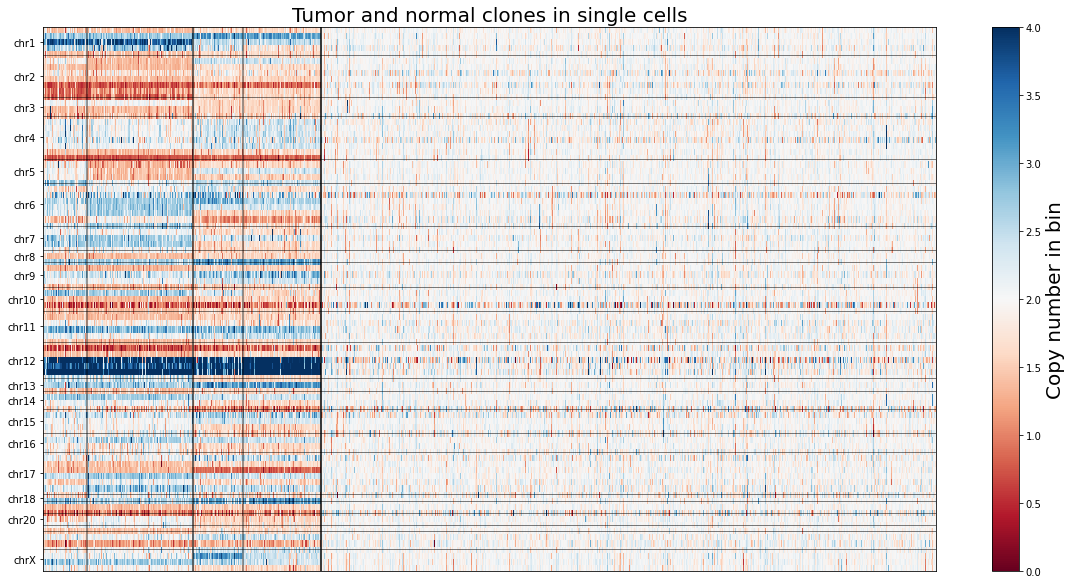

In [123]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values).values.astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [124]:
lines = sorted([l[1] for l in vlines])+[np.inf]

In [125]:
pl_list = CN_list

In [126]:
l = lines[0]
c = pl_list[0]
j = 0
lines, CN_list


([125, 424, 566, 788, inf], [3.9, 2.8600000000000003, 2.54, 2.46, 1.98])

In [127]:
cell_ploidies = []
for i in range(len(q_data.columns)):
    if i<l:
        cell_ploidies.append(c)
    if i == l: 
        j = j+1
        l = lines[j]
        c = pl_list[j]
        cell_ploidies.append(c)


In [128]:
q_data_quantal_CN = pd.DataFrame()

In [129]:
name = q_data.columns[0]
col = q_data[name]


In [130]:
count = 0
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies[count]).apply(round)
    count = count+1

In [131]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data.values)):
    l = q_data.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [132]:
data["len_image"] = (data["len_factor"]//10).values

In [133]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [134]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

1.0
0.75
0.5
0.5


Text(0.5, 1.0, 'Tumor and normal populations in single cells')

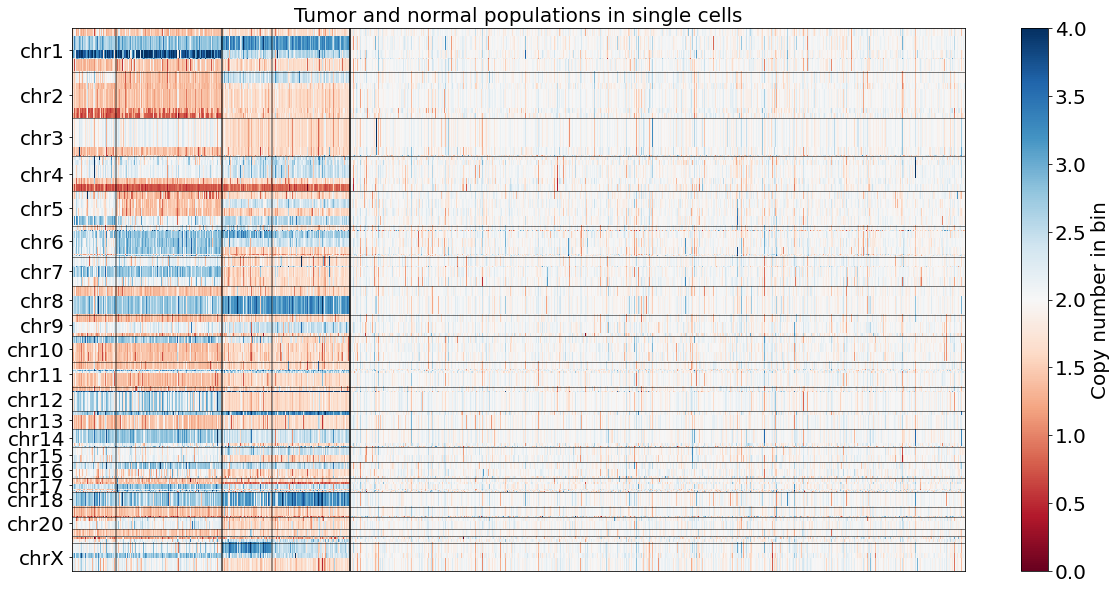

In [135]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)

In [136]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

788 1.0
424 0.75
125 0.5
566 0.5


Text(0.5, 1.0, 'Tumor and normal clones in single cells')

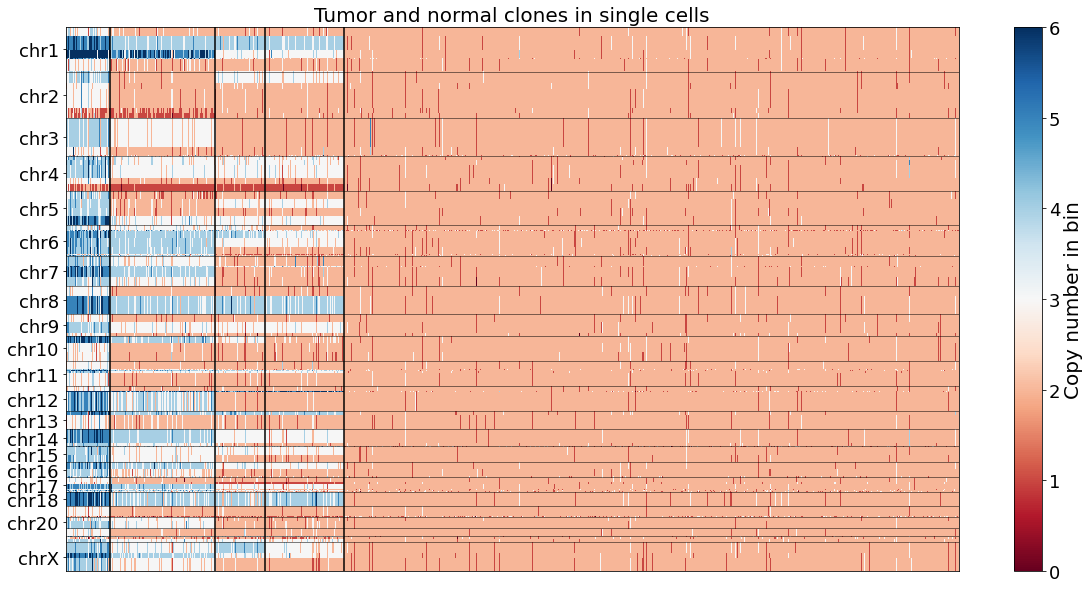

In [137]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(l[1],1 - l[0]*L)
    plt.axvline(l[1], color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [138]:
clusters = []
current = 0
c = 1
row_list = []
for l in sorted(lines):
    cl = []
    for i in new_order[current:l]:
        cl.append(all_data.columns[i])
        row_list.append({"cell":all_data.columns[i], "cluster" : c})
    clusters.append(cl)
    c = c+1
    current = l
cl = []
for i in new_order[current:]:
    cl.append(all_data.columns[i])
    row_list.append({"cell":all_data.columns[i], "cluster" : c})
clusters.append(cl)

In [139]:
mult_KV = []
for cl in clusters:
    mult_KV.append(((all_data[cl].sum(axis = 1))/(all_data[cl].sum(axis = 1)).sum()).values)

mult_KV = np.array(mult_KV)
member_dict = dict()
log_member_dict = dict()

In [140]:
clusters1 = [[] for cl in clusters]
membership = []
l_membership = []
membership_arg = []
excep = []
excep_M = []

for c in output_cell_list:
    L = np.dot(np.log(mult_KV),all_data[c].values)
    lM = L - logsumexp(L)
    M = np.exp(lM)
    member_dict[c] = M
    log_member_dict[c] = lM
    l_membership.append(lM)
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters1[np.argmax(M)].append(c)
    if max(M)<0.9:
        excep.append(c)
        excep_M.append(M)

In [141]:
normal_read_mean = all_data[normal_cells].sum().mean()

In [142]:
5

5

In [143]:
cluster_count_means = []
for cl in clusters1:
    cluster_count_means.append(all_data[cl].sum().mean())
    print(all_data[cl].sum().mean()/normal_read_mean)

1.2493593656042
1.2630218381335858
1.1296812034079258
1.195350774057337
0.9966698860992741


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


1.66 0.8772118386109202
2.2199999999999998 0.5177136572705794
2.94 0.5536695238671833
3.9 0.402379624233534
4.7 0.5157048012892296
5.140000000000001 0.3262640843871639
5.42 0.41999214643433797
 


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


1.62 0.8511197938766681
1.98 0.3843220090999613
2.2199999999999998 0.45674559297539696
2.8600000000000003 0.6156779909000387
3.7800000000000002 0.3816518165557001
4.140000000000001 0.7021535919099458
4.34 0.611319365967607
4.46 0.47614715244900285
5.26 0.36330278529404003
 
2.54 0.7437830251807807
3.62 0.40297055612534893
5.02 0.885035719456047
 


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


2.46 0.7657743348543964
3.42 0.21949946547710325
3.58 0.4040073366297265
3.86 0.22406176574747602
4.9399999999999995 0.9559983719384065
 
1.98 1.0
2.98 0.0
3.98 1.0
4.98 0.0
 


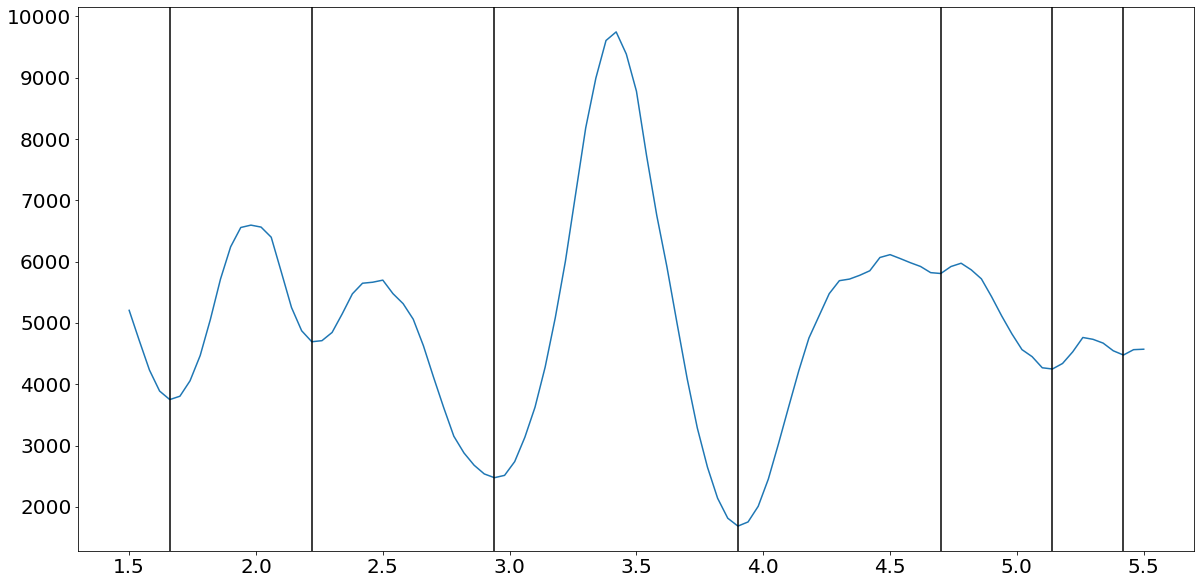

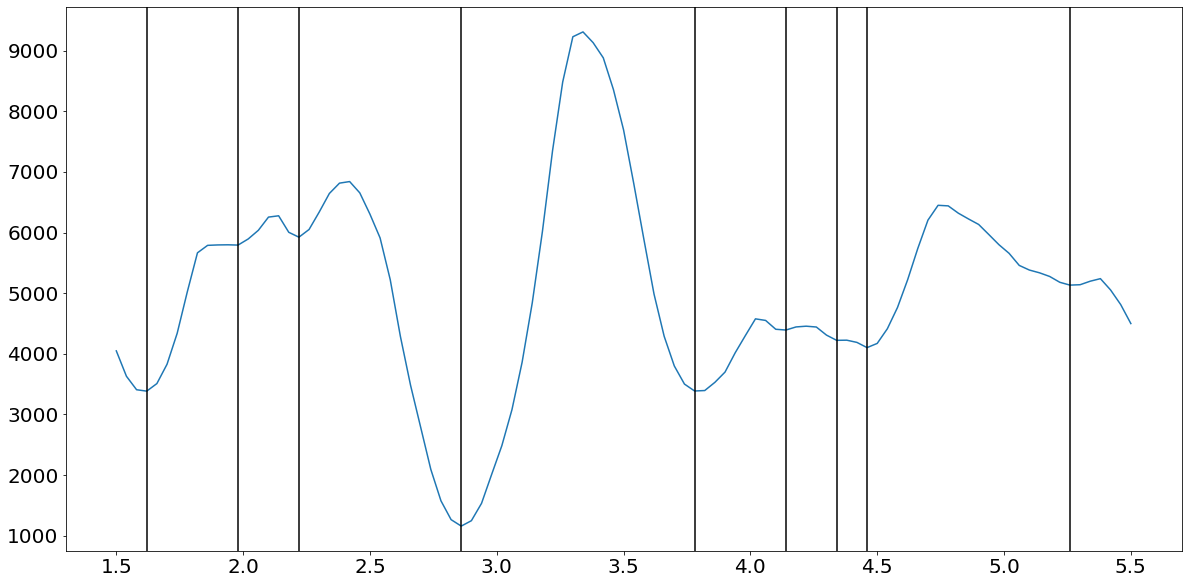

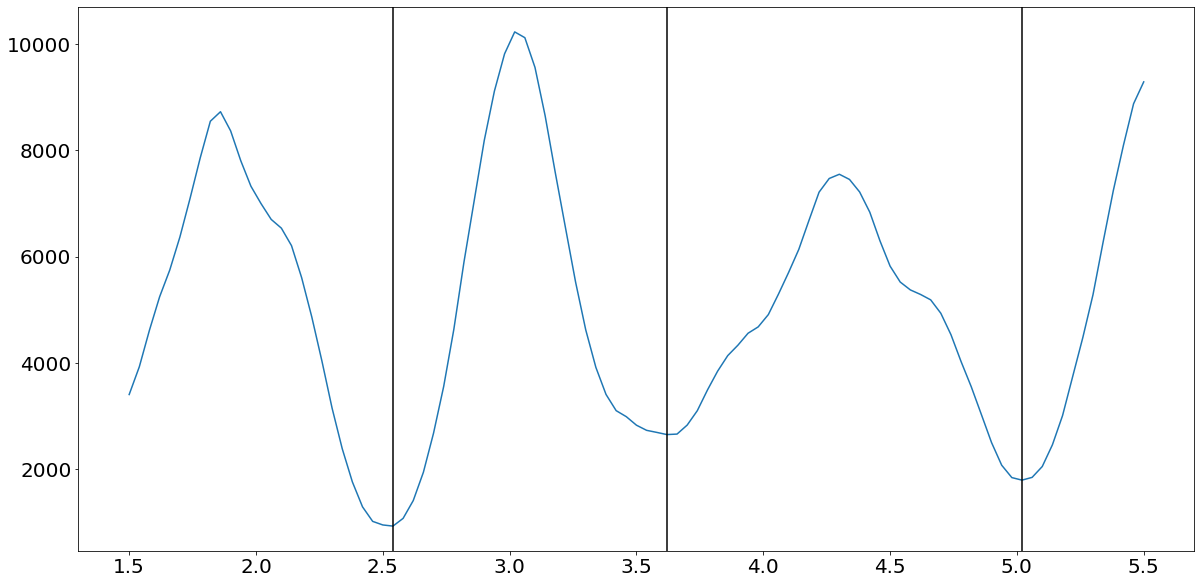

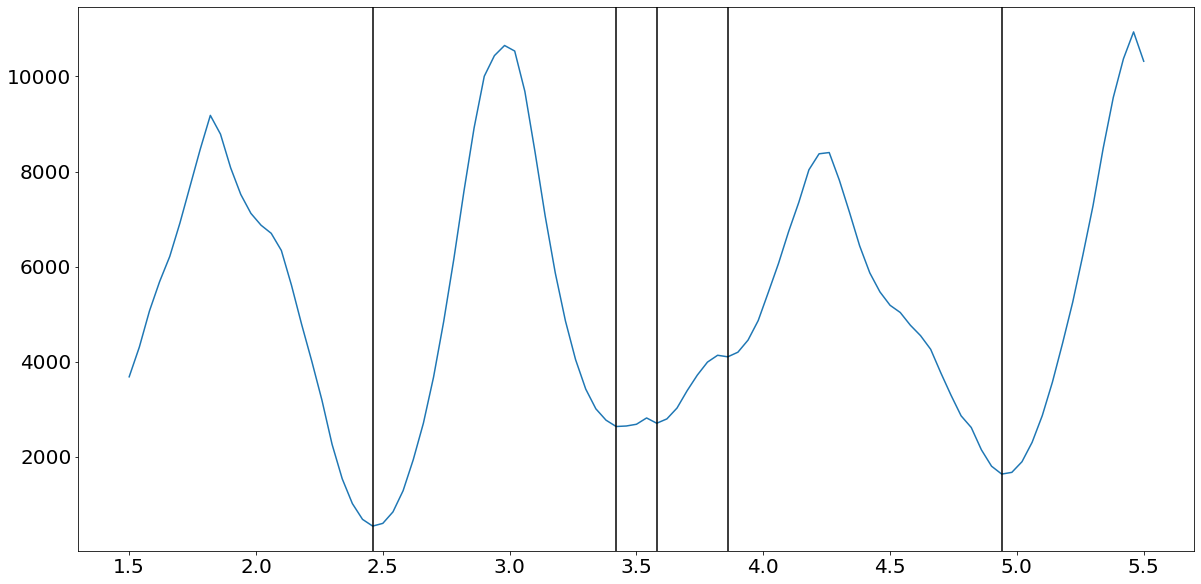

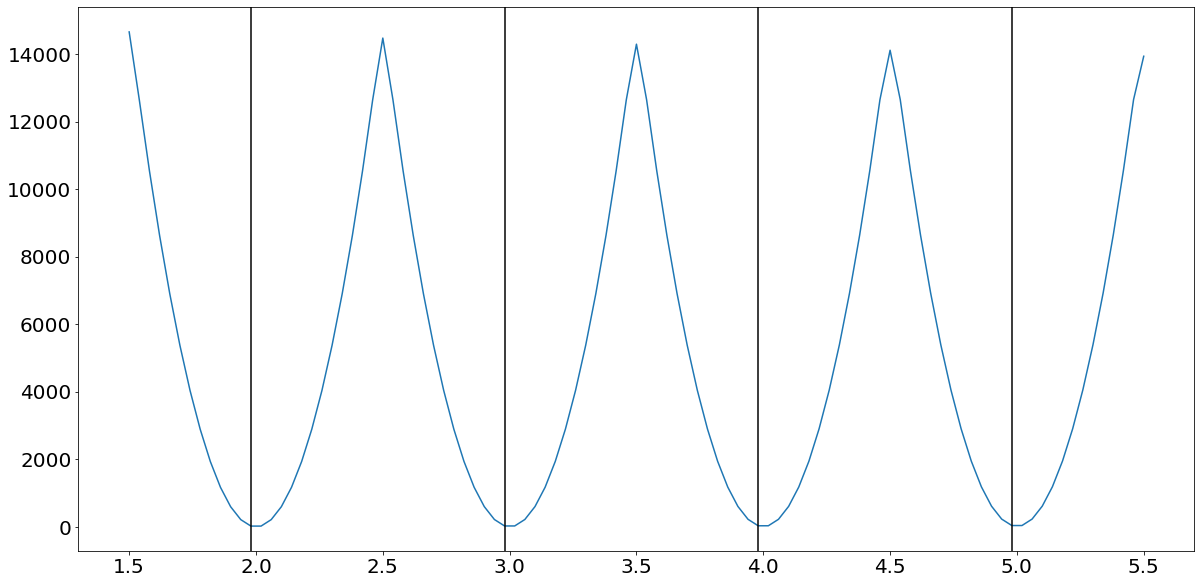

In [144]:
new_output_list = []
vlines = []
l = 0
cell_ploidies = []
cluster_ploidies = []
for cl in clusters1:
    vlines.append(l)
    new_output_list = new_output_list+cl
    l = l+len(cl)
    pl = balanced_ploidy(cl)
    cell_ploidies = cell_ploidies+[pl for c in cl]
    cluster_ploidies.append(pl)
vlines.append(l)


In [145]:
def balanced_ploidy_read_counts(cl, all_data, normal_read_mean):
    T_df = hap_count_df[hap_count_df["cell"].isin(cl)]
    bin_groups = T_df.groupby("bin")
    
    binstart = bins_df["bin"].values
    ratio = []
    for b in binstart:
        df = bin_groups.get_group(b)
        p = df["hap_count"].sum()/df["Total"].sum()
        ratio.append((min(p,1-p)))
    
    bins_df["T_ratio"] = ratio
    
    seg_grps = bins_df.groupby("seg")
    T_al = []
    
    for s in bins_df["seg"].unique():
        segment = seg_grps.get_group(s)
        T_al.append(segment["T_ratio"].mean())
        
    T_al_balance = np.array([int(t>0.4) for t in T_al])
    col = all_data[cl].sum(axis = 1)
    
    normal_factor = data["normal_average"].values
    totlen = sum(normal_factor)
    
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    out = ploidy(Z,X,Y)
    all_pl = ploidy_list(out)
    fig,ax = plt.subplots(1, figsize=(20, 10))
    plt.plot(out[0], out[1])
    for l in all_pl:
        plt.axvline(l[0], color = "black")
    
    bl_ratio = []
#     print(Z)
#     print(T_al_balance)
    for p in all_pl:
        pl = p[0]
        CN = np.array([int(round(z)%2==0) for z in Z*pl])
        #print([round(z) for z in Z*pl])
        b =  sum((CN*T_al_balance)*normal_factor)/sum(T_al_balance*normal_factor)
        bl_ratio.append(b)
        print(pl, b)
    
    pl_read_count = 2*(all_data[cl].sum().mean()/normal_read_mean)
    
    print(" ")
    
    
    sorted_indices = sorted(range(len(bl_ratio)), key=lambda x: bl_ratio[x], reverse = True)
    
    sorted_indices = [i for i in sorted_indices if bl_ratio[i]>0.7]
    
    
    pos_pl = [all_pl[s][0] for s in sorted_indices]
    
    try:
        best_pl = min(pos_pl, key=lambda x: abs(x - pl_read_count))
    except:
        s = np.argmax(bl_ratio)
        best_pl = all_pl[s][0]
    
    print(pl_read_count, pos_pl)
    
    print(" ")
    
    
    #best_pl = all_pl[np.argmax(bl_ratio)][0]
    
    
    return best_pl

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


1.66 0.8772118386109202
2.2199999999999998 0.5177136572705794
2.94 0.5536695238671833
3.9 0.402379624233534
4.7 0.5157048012892296
5.140000000000001 0.3262640843871639
5.42 0.41999214643433797
 
2.4987187312084 [1.66]
 


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


1.62 0.8511197938766681
1.98 0.3843220090999613
2.2199999999999998 0.45674559297539696
2.8600000000000003 0.6156779909000387
3.7800000000000002 0.3816518165557001
4.140000000000001 0.7021535919099458
4.34 0.611319365967607
4.46 0.47614715244900285
5.26 0.36330278529404003
 
2.5260436762671716 [1.62, 4.140000000000001]
 
2.54 0.7437830251807807
3.62 0.40297055612534893
5.02 0.885035719456047
 
2.2593624068158515 [5.02, 2.54]
 


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in long_scalars
  if __name__ == '__main__':


2.46 0.7657743348543964
3.42 0.21949946547710325
3.58 0.4040073366297265
3.86 0.22406176574747602
4.9399999999999995 0.9559983719384065
 
2.390701548114674 [4.9399999999999995, 2.46]
 
1.98 1.0
2.98 0.0
3.98 1.0
4.98 0.0
 
1.9933397721985482 [1.98, 3.98]
 


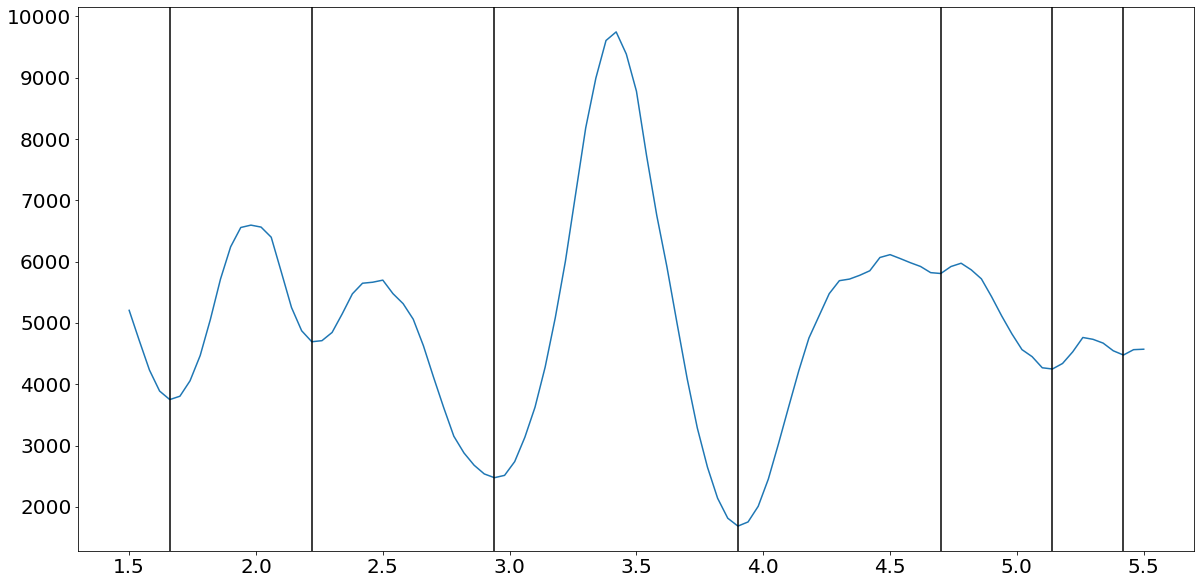

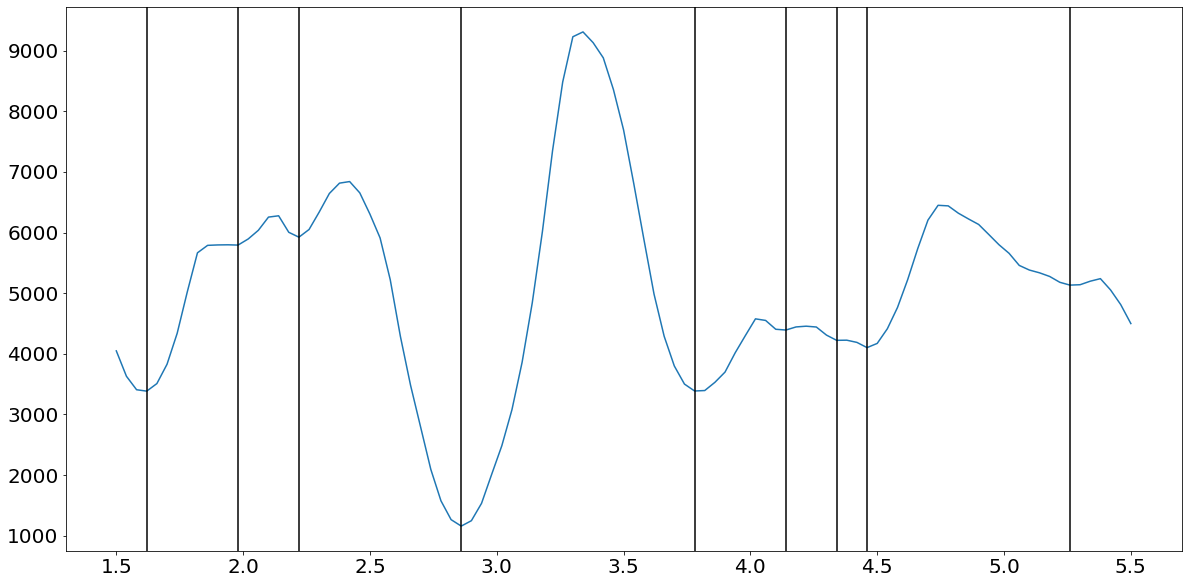

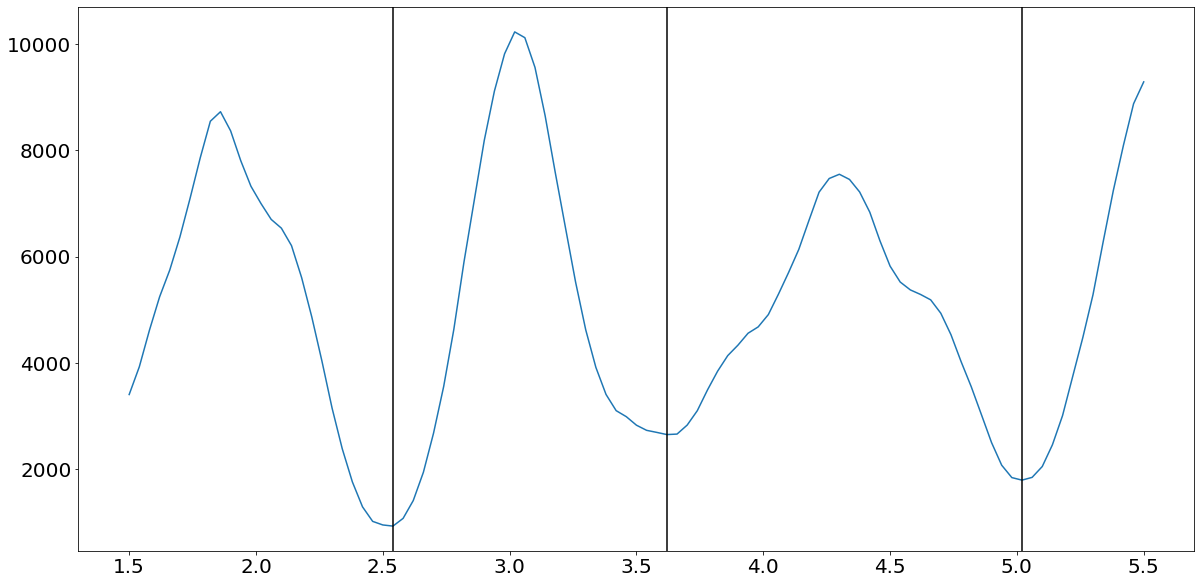

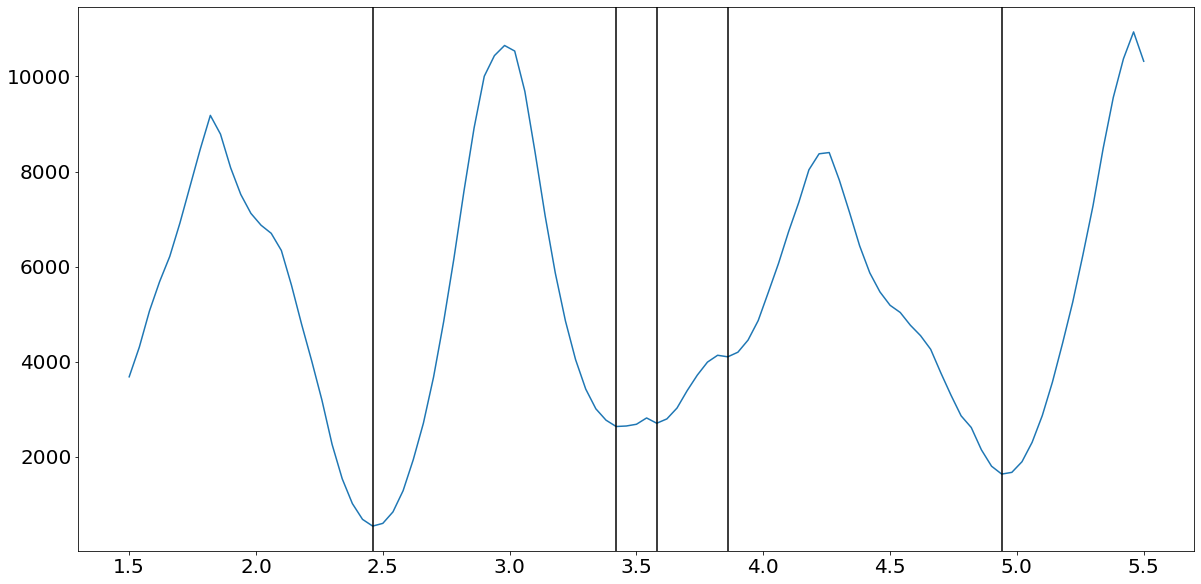

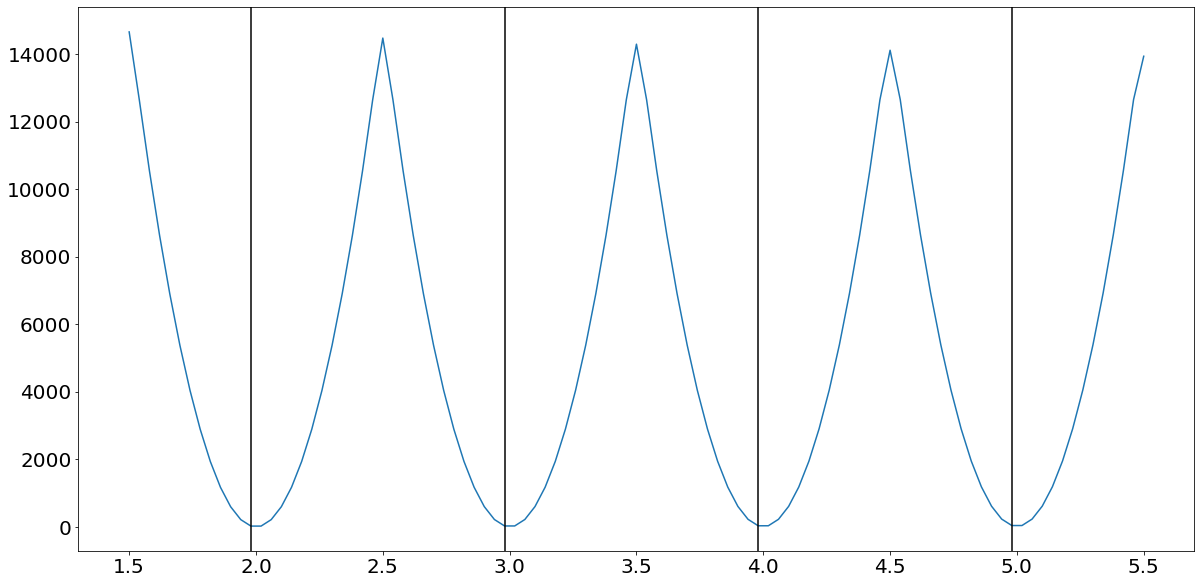

In [146]:
new_output_list = []
vlines = []
l = 0
cell_ploidies = []
cluster_ploidies = []
CN_list = []
for cl in clusters1:
    vlines.append(l)
    new_output_list = new_output_list+cl
    l = l+len(cl)
    pl = balanced_ploidy_read_counts(cl, all_data, normal_read_mean)
    cell_ploidies = cell_ploidies+[pl for c in cl]
    cluster_ploidies.append(pl)
    
    col = all_data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    CN = np.array([round(z) for z in Z*pl])
    
    CN_list.append(CN)
    
vlines.append(l)

In [147]:
cluster_ploidies

[1.66, 1.62, 2.54, 2.46, 1.98]

In [148]:

my_list = [5, 2, 9, 1, 4]

# Get the indices of the sorted list
sorted_indices = sorted(range(len(my_list)), key=lambda x: my_list[x], reverse=True)

print(sorted_indices)

[2, 0, 4, 1, 3]


In [149]:
q_data = q_data[new_output_list]
q_data_quantal_CN = pd.DataFrame()
name = q_data.columns[0]
col = q_data[name]


In [150]:
count = 0
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies[count]).apply(round)
    count = count+1

In [151]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data.values)):
    l = q_data.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [152]:
data["len_image"] = (data["len_factor"]//10).values

In [153]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [154]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

(0.0, 2533.0)

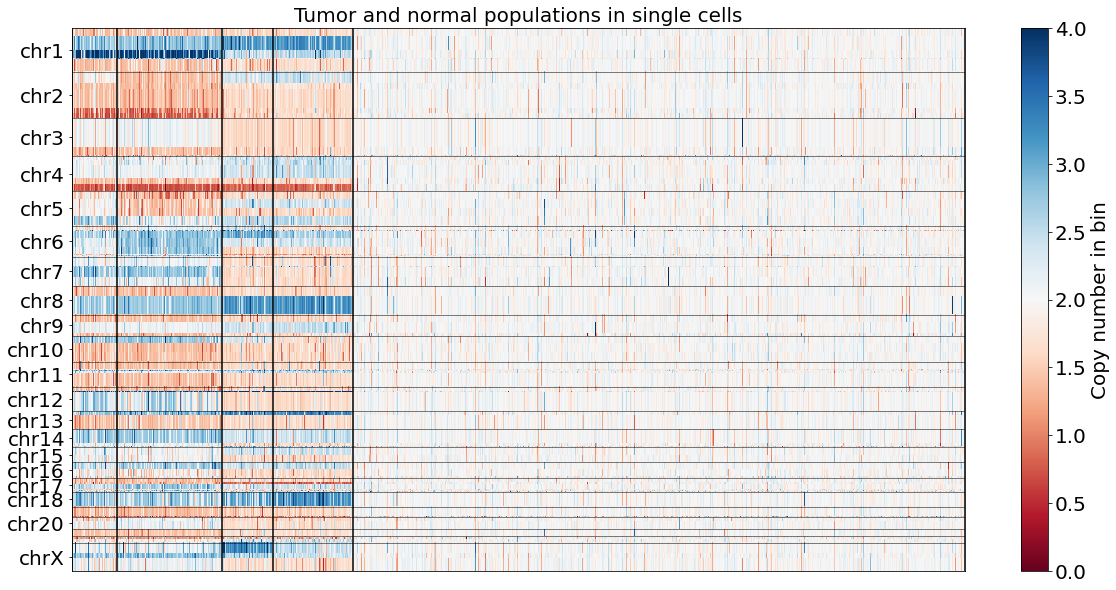

In [155]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
for l in vlines:
    plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)
plt.xlim([vlines[0], vlines[-1]])

In [156]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [157]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:2: MatplotlibDeprecationWarning: Passing parameters norm and vmin/vmax simultaneously is deprecated since 3.3 and will become an error two minor releases later. Please pass vmin/vmax directly to the norm when creating it.
  


(0.0, 2533.0)

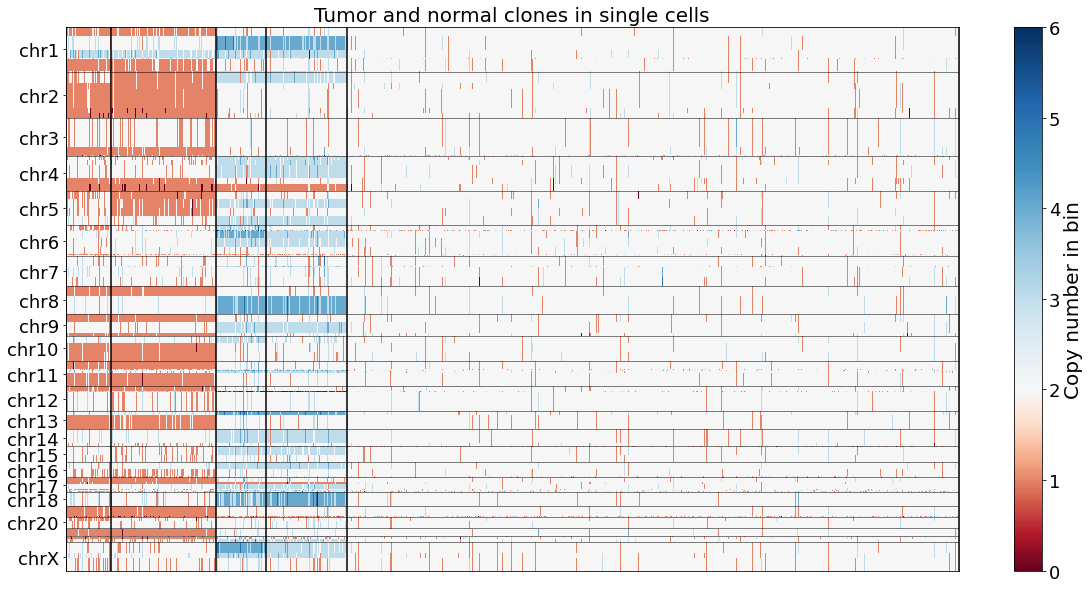

In [158]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    #print(l[1],1 - l[0]*L)
    plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)
plt.xlim([vlines[0], vlines[-1]])

In [ ]:
scope = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/t57/cell_names_t57_SCOPE.txt", header = None)[0].values

In [ ]:
scope

In [ ]:
set(cell_ploidies)

In [ ]:
T1 = clusters1[2]

In [ ]:
pl = 2.8
temp_df = pd.DataFrame()
for name in T1:
    col = q_data[name]
    temp_df[name] = ((col/col.mean())*pl).apply(round)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(temp_df[T1].values)):
    l = temp_df[T1].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor profile with ploidy "+str(pl), fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
T2 = clusters1[3]

In [ ]:
pl = 3.45
temp_df = pd.DataFrame()
for name in T2:
    col = q_data[name]
    temp_df[name] = ((col/col.mean())*pl).apply(round)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(temp_df[T2].values)):
    l = temp_df[T2].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor profile with ploidy "+str(pl), fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
df_list = []
normal_cluster_count = 1
tumor_cluster_count = 1
for cl in clusters1:
    df = pd.DataFrame()
    df["cells"] = cl
    print(len([c for c in cl if c in normal_cells])/len(cl))
    if (len([c for c in cl if c in normal_cells])/len(cl))>0.6:
        df["clusters"] = "Normal_"+str(normal_cluster_count)
        normal_cluster_count = normal_cluster_count+1
        
    else:
        df["clusters"] = "Tumor_"+str(tumor_cluster_count)
        tumor_cluster_count = tumor_cluster_count+1
    df_list.append(df)
multinomial_clusters = pd.concat(df_list)

In [ ]:
num_normal_cells =len(multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"])

In [ ]:
multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"]["cells"].values

In [ ]:
len(len_adjusted_quantal)

In [ ]:
len(cells)

In [ ]:
possible_chrom_loss_normals = []
for c in multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"]["cells"].values:
    counter = 0
    for val in q_data_quantal_CN[c].values:
        if val==0:
            counter+=1
    if counter>1:
        possible_chrom_loss_normals.append(c)

In [ ]:
h_lines

In [ ]:
len(possible_chrom_loss_normals)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data[possible_chrom_loss_normals].values)):
    l = q_data[possible_chrom_loss_normals[:20]].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [ ]:
data["len_image"] = (data["len_factor"]//10).values

In [ ]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [ ]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
# for l in vlines:
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN[possible_chrom_loss_normals].values)):
    l = q_data_quantal_CN[possible_chrom_loss_normals[:20]].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Normal cells", fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
q_data_quantal_CN[possible_chrom_loss_normals]

In [ ]:
normal_first = [list(l[-num_normal_cells:])+list(l[:-num_normal_cells]) for l in len_adjusted_quantal]

In [ ]:
vlines

In [ ]:
new_vlines = [0, num_normal_cells]+[v+num_normal_cells for v in vlines[1:-1]]

In [ ]:
# fig,ax = plt.subplots(1,figsize=(20, 10))
# h = ax.imshow(normal_first, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
# #fig.colorbar(h)
# cbar = fig.colorbar(h)
# L = 1/len(new_vlines)
# #lines = [l[1] for l in vlines]
# ax.set_xticks([])
# ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
# ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

# plt.rc('xtick', labelsize=20) 
# plt.rc('ytick', labelsize=20)
# for l in new_vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
# for l in h_lines[:-1]:
#     plt.axhline(l, color = "black", linewidth=0.5)

# cbar.set_label("Copy number in bin", fontsize = 20)

# plt.title("Tumor and normal clones without the broken cells", fontsize = 20)
# plt.xlim([vlines[0], vlines[-1]])

In [ ]:
#multinomial_clusters.to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".multinomial_clusters.txt", sep = "\t", index = None)

In [ ]:
membership = []
l_membership = []
for c in new_output_list:
    M = member_dict[c]
    lM = log_member_dict[c]
    l_membership.append(lM)
    membership.append(M)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4])
ax.set_yticklabels(["T1","T2", "T3","T4","Normal"])
ax.imshow(np.transpose(l_membership),interpolation='nearest', aspect='auto')
plt.title("Log-membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4])
ax.set_yticklabels(["T1","T2", "T3","T4","Normal"])
ax.imshow(np.transpose(membership),interpolation='nearest', aspect='auto')
plt.title("Membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count.txt", sep = "\t")

In [ ]:
stop

In [ ]:
#read_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".read_counts.txt", sep = "\t", header = None) 

In [ ]:
#pd.DataFrame(row_list).to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/multinomial_clusters_no_adjust.txt", sep = "\t", index = None)

In [ ]:
read_count_df.head()

In [ ]:
read_count_dict = dict(zip(read_count_df[0].values, read_count_df[1].values))

In [ ]:
normals = clusters[-1]

In [ ]:
fig,ax = plt.subplots(1, figsize=(20, 10))
counts = read_count_df[read_count_df[0].isin(normals)][1].values
plt.hist(counts, bins = 20, alpha = 0.4, label = "Normal")

# plt.show()
# fig,ax = plt.subplots(1, figsize=(20, 10))
counts = read_count_df[~read_count_df[0].isin(normals)][1].values
plt.hist(counts, bins = 20, alpha = 0.4, label = "Tumor")
plt.xlabel("Unique read counts",fontsize = 20)
plt.ylabel("Number of nuclei",fontsize = 20)
plt.legend(fontsize = 20)

In [ ]:
avg_counts = []
for cl in clusters:
    fig,ax = plt.subplots(1, figsize=(20, 10))
    counts = read_count_df[read_count_df[0].isin(cl)][1].values
    avg_counts.append(sum(counts)/len(counts))
    plt.hist(counts, alpha = 0.4)
    plt.show()

In [ ]:
normal_avg = avg_counts[-1]
normal_ploidy = CN_list[-1]

In [ ]:
for a in avg_counts:
    print((a/normal_avg)*normal_ploidy)

In [ ]:
bar_lists = []
for cl in clusters:
    B = []
    for name in names_list:
        G = seurat_G.get_group(name)
        n = len([name for name in G[0].values if name in cl])
        B.append(n)
    bar_lists.append(np.array(B))

In [ ]:
#names_list = ["TumorA", "TumorB", "Normal"]

In [ ]:
prev = np.zeros(len(names_list))
fig,ax = plt.subplots(1, figsize=(20, 10))
for B in bar_lists:
    plt.bar(names_list, B, bottom = prev)
    prev = prev+B

In [ ]:
mult_KV = []
for cl in clusters:
    mult_KV.append(((all_data[cl].sum(axis = 1))/(all_data[cl].sum(axis = 1)).sum()).values)

In [ ]:
mult_KV = np.array(mult_KV)

In [ ]:
member_dict = dict()
log_member_dict = dict()

In [ ]:
clusters1 = [[] for cl in clusters]
membership = []
l_membership = []
membership_arg = []
excep = []
excep_M = []

for c in output_cell_list:
    L = np.dot(np.log(mult_KV),all_data[c].values)
    lM = L - logsumexp(L)
    M = np.exp(lM)
    member_dict[c] = M
    log_member_dict[c] = lM
    l_membership.append(lM)
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters1[np.argmax(M)].append(c)
    if max(M)<0.9:
        excep.append(c)
        excep_M.append(M)

In [ ]:
new_output_list = []
for cl in clusters1:
    new_output_list = new_output_list+cl


In [ ]:
# hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count_WGS_seg.txt", sep = "\t")
# hap_count_df.head()
# bin_list = sorted(hap_count_df["bin"].unique())
# hap_type = dict()
# bin_list = sorted(hap_count_df["bin"].unique())
# for b in bin_list:
#     print(b)
#     bin_info = hap_count_df[hap_count_df["bin"]==b]
#     h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#     hap_type[b] = int(h>=0.5)
# hap_grps = hap_count_df.groupby("seg")

In [ ]:
for cl in clusters1:
    print(len(cl))

In [ ]:
cl = clusters1[0]

In [ ]:
balance_array = []
col = data[cl].sum(axis = 1)
Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
for s in range(len(Z)):
    hap = hap_grps.get_group(s)
    sub_hap = hap[hap["cell"].isin(cl)]
    hap_fractions_min = []
    bin_list = sorted(sub_hap["bin"].unique())
    num = 0
    den = 0
    for b in bin_list:
        bin_info = sub_hap[sub_hap["bin"]==b]
        #h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
        den = bin_info["Total"].sum()
        s = bin_info["hap_count"].sum()
        h = s/den
        if h<=0.5:
            num = s
        else:
            num = den - s
    al = num/den
    print(al)
    balance_array.append(int((al>0.4)))

In [ ]:
all_data.head()

In [ ]:
data.head()

In [ ]:
totlen

In [ ]:
normal_factor = data["normal_average"].values

In [ ]:
pl_cluster_dict = dict()
count = 0
for cl in clusters1:
    col = data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    
    balance_array = []
    for s in range(len(Z)):
        hap = hap_grps.get_group(s)
        sub_hap = hap[hap["cell"].isin(cl)]
        hap_fractions_min = []
        bin_list = sorted(sub_hap["bin"].unique())
        for b in bin_list:
            bin_info = sub_hap[sub_hap["bin"]==b]
            h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
            hap_fractions_min.append(min(h, 1-h))
        al = sum(hap_fractions_min)/len(hap_fractions_min)
        balance_array.append(int((al>0.4)))

    
    #print(Z)
    out = ploidy(Z,X,Y)
    #print(out)
    all_pl = ploidy_list(out)
    print(all_pl)
    
    balance_pl = []
    
    for p in all_pl:
        pl = p[0]
        b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
        balance_pl.append(1-b)
        #print(pl, b)
        
    
#     best_pl = all_pl[np.argmax(balance_pl)][0]
    print(balance_pl)
    print(np.argsort(balance_pl))
    for ind in np.argsort(balance_pl):
        best_pl = all_pl[ind][0]
        if sum([round(z)==0 for z in Z*best_pl])==0:
            break
        else:
            print(Z*best_pl)
    pl_cluster_dict[count] = best_pl
    count = count+1

In [ ]:
def balanced_ploidy(cl):
    balance_array = []
    col = data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    for s in range(len(Z)):
        hap = hap_grps.get_group(s)
        sub_hap = hap[hap["cell"].isin(cl)]
        hap_fractions_min = []
        bin_list = sorted(sub_hap["bin"].unique())
        for b in bin_list:
            bin_info = sub_hap[sub_hap["bin"]==b]
            h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
            hap_fractions_min.append(min(h, 1-h))
        al = sum(hap_fractions_min)/len(hap_fractions_min)
        balance_array.append(int((al>0.4)))

    
    #print(Z)
    out = ploidy(Z,X,Y)
    #print(out)
    all_pl = ploidy_list(out)
    print(all_pl)
    
    balance_pl = []
    
    for p in all_pl:
        pl = p[0]
        b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
        balance_pl.append(1-b)
        #print(pl, b)
        
    
#     best_pl = all_pl[np.argmax(balance_pl)][0]
    print(balance_pl)
    print(np.argsort(balance_pl))
    for ind in np.argsort(balance_pl):
        best_pl = all_pl[ind][0]
        if sum([round(z)==0 for z in Z*best_pl])==0:
            break
        else:
            print(Z*best_pl)

    return best_pl

In [ ]:
A = np.array(out[1])
B = A[1:]-A[:-1]
B0 = B[:-1]
B1 = B[1:]
I = np.where((B0<0) & (B1>0))[0] 
#sorted(dict(zip([out[0][i] for i in I],[out[1][i] for i in I])).items(), key=lambda item: item[1])

In [ ]:
plt.plot(out[0], out[1])

In [ ]:
cluster_ploidies = []
cell_ploidies_dict = {}
row_list = []

for count in range(len(clusters1)):
    cl = clusters1[count]
    
    for name in cl:
        row_list.append({"cell":name, "cluster" : count})
        cell_ploidies_dict[name] = pl_cluster_dict[count]



In [ ]:
pl_cluster_dict

In [ ]:
pd.DataFrame(row_list)

In [ ]:
#pd.DataFrame(row_list).to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/multinomial_clusters.txt", sep = "\t", index = None)

In [ ]:
data["cum_length"] = data["normal_average"].cumsum()
totlen = sum(data["normal_average"])
X = [0]+list(data["cum_length"].values[:-1])
Y = data["cum_length"].values

In [ ]:
count = 0
q_data = q_data[new_output_list]
q_data_quantal_CN = pd.DataFrame()
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies_dict[name]).apply(round)
    count = count+1

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [ ]:
membership = []
l_membership = []
for c in new_output_list:
    M = member_dict[c]
    lM = log_member_dict[c]
    l_membership.append(lM)
    membership.append(M)

In [ ]:
# mem_for_image = []
# for l in np.transpose(l_membership):
#     for i in range(100):
#         mem_for_image.append(l)
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4,5])
ax.set_yticklabels(["T1", "T2", "T3", "T4","T5","Normal"])
ax.imshow(np.transpose(l_membership),interpolation='nearest', aspect='auto')
plt.title("Log-membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
# mem_for_image = []
# for l in np.transpose(membership):
#     for i in range(100):
#         mem_for_image.append(l)
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4,5])
ax.set_yticklabels(["T1", "T2", "T3", "T4","T5","Normal"])
plt.imshow(np.transpose(membership),interpolation='nearest', aspect='auto', vmin = 0, vmax = 1)
plt.title("Membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
for cl in clusters:
    print(len([c for c in cl if c in normal_cells]))

In [ ]:
for cl in clusters1:
    print(len([c for c in cl if c in normal_cells]))

In [ ]:
for M in excep_M:
    print([round(m,2) for m in M])

In [ ]:
for i in np.where(np.array(membership_arg)==0)[0]:
    print([round(m,2) for m in membership[i]])

In [ ]:
#data["normal_average"]

In [ ]:
cl = clusters1[-1]

In [ ]:
col = all_data[cl].sum(axis = 1)
        
Z = ((col/sum(col))*totlen)/data["normal_average"]

In [ ]:
out = ploidy(Z,X,Y)
all_pl = ploidy_list(out)
        

In [ ]:
pl = []
lens = np.array(Y)-np.array(X)
for i in range(len(all_pl)):
#print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
    if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
        pl.append(all_pl[i][0])


#pl = sorted(pl)

In [ ]:
pl

In [ ]:
cluster_ploidies

In [ ]:
cl0 = clusters1[0]
cl1 = clusters1[-1]
prop = np.array([cluster_ploidies[0], cluster_ploidies[-1]])/(cluster_ploidies[0]+cluster_ploidies[-1])

In [ ]:
prop[0]*mult_KV[0] + prop[1]*mult_KV[-1]

In [ ]:
mult_big_KV = []
cluster_names = []
count = 0
for m in mult_KV:
    mult_big_KV.append(m)
    cluster_names.append(count)
    count = count+1

for (i, j) in itertools.combinations(range(len(clusters1)), 2):
    prop = np.array([cluster_ploidies[i], cluster_ploidies[j]])/(cluster_ploidies[i]+cluster_ploidies[j])
    mult_big_KV.append(prop[0]*mult_KV[i] + prop[1]*mult_KV[j])
    cluster_names.append((i,j))

In [ ]:
clusters_col = [[] for m in mult_big_KV]
mult_big_KV = np.array(mult_big_KV)
membership = []
membership_arg = []
excep = []
excep_M = []
for c in cells:
    L = np.dot(np.log(mult_big_KV),all_data[c].values)
    M = np.exp(L - logsumexp(L))
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters_col[np.argmax(M)].append(c)
    if max(M)<0.8:
        excep.append(c)
        excep_M.append(M)

In [ ]:
len(excep_M)

In [ ]:
for c, M in zip(excep,excep_M):
    print(c)
    print([(name,round(m,2)) for m, name in zip(M, cluster_names) if round(m,2)!=0])

In [ ]:

for cl,name in zip(clusters_col,cluster_names):
    print(name,len(cl))

In [ ]:
balanced_ploidy(cl)

In [ ]:
def make_quantal_plot(reg_table, cl, title = "multiple ploidies cluster plot"):
     
    n_ind = False
    
    chrom_ends = reg_table[reg_table["chrom"]!=reg_table.shift()["chrom"]]["new_pos_start"].values
    
    col = reg_table[cl].sum(axis = 1)
    reg_table["cum_length"] = reg_table["normal_average"].cumsum()
    totlen = sum(reg_table["normal_average"])
    
    
    X = reg_table["new_pos_start"].values
    Y = reg_table["new_pos_end"].values
    X1 = [0]+list(reg_table["cum_length"].values[:-1])
    Y1 = reg_table["cum_length"].values
    Z = ((col/sum(col))*totlen)/(reg_table["normal_average"])
    
    reg_table["temp"] = Z
    pl = balanced_ploidy(cl)
    
#     out = ploidy(Z,X1,Y1)
#     all_pl = ploidy_list(out)
    
#     pl = []
#     lens = np.array(Y1)-np.array(X1)
#     for i in range(len(all_pl)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#         if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
            
#             pl.append(all_pl[i][0])
            
#     reg_table["temp"] = (pl[0]*Z).apply(lambda x : round(x))
    #reg_table["temp"] = pl[0]*Z
    CN = pl*Z
    Z = reg_table["temp"].values
    
    fig,ax = plt.subplots(1, figsize=(20, 10))
    for i in range(len(X)):
    #    ax2 = ax.twinx()
#         ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
#         ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        ax.plot([X[i],Y[i]], [CN[i],CN[i]], color = "black")
        if i!=(len(X)-1):
            ax.plot([Y[i],X[i+1]], [CN[i],CN[i+1]], color = "grey")
        
    
    
    if len(reg_table["temp"].unique())==1:
        #print("Normal")
        #plt.title(title + " Normal")
        n_ind = True
    #else:
        #plt.title(title)

    plt.xlim([X[0], Y[-1]])
    
    def switch_pl1(x):
        return (pl[0][0]/pl[1][0])*x


    def switch_pl2(x):
        return (pl[1][0]/pl[0][0])*x
    
    #secax = ax.secondary_yaxis('right', functions=(switch_pl1, switch_pl2))

    i = 0
    for ch in chrom_ends:
            plt.axvline(ch)
            if i in range(18):
                plt.text(ch+2,0.05, str(i+1), fontsize=20)
            if i ==22:
                plt.text(ch+2,0.05, "X",fontsize=20)  
            i = i+1
            
#     for i in range(len(chrom_ends)):
#         if i in range(18):
#             plt.text(chrom_ends[i]+2,0.05, str(i+1))
#         if i ==22:
#             plt.text(chrom_ends[i]+2,0.05, "X")

    for i in range(1,10):
        plt.axhline(i, color = "blue", alpha = 0.2)
        #for p in pl[1:]:
        #plt.axhline(i*(pl[0]/pl[1]),color = "red",alpha = 0.2)
        
    plt.ylim([0,9])
    ax.set_xticks([])
    return CN, n_ind

In [ ]:
data["length"] = data["new_pos_end"]-data["new_pos_start"]

In [ ]:
data.head()

In [ ]:
i = 0
for cl in clusters1:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(i))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
#n_clust

In [ ]:
i = 0
for cl in clusters_col:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(cluster_names[i]))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
mult_big_KV = []
cluster_names = []
count = 0
for m in mult_KV:
    mult_big_KV.append(m)
    cluster_names.append(count)
    count = count+1
j = n_clust
for i in range(len(clusters1)):
    if i==n_clust:
        continue
    prop = np.array([cluster_ploidies[i], cluster_ploidies[j]])/(cluster_ploidies[i]+cluster_ploidies[j])
    mult_big_KV.append(prop[0]*mult_KV[i] + prop[1]*mult_KV[j])
    cluster_names.append((i,j))


In [ ]:
clusters_col = [[] for m in mult_big_KV]
mult_big_KV = np.array(mult_big_KV)
membership = []
membership_arg = []
excep = []
excep_M = []
for c in cells:
    L = np.dot(np.log(mult_big_KV),all_data[c].values)
    M = np.exp(L - logsumexp(L))
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters_col[np.argmax(M)].append(c)
    if max(M)<0.8:
        excep.append(c)
        excep_M.append(M)

In [ ]:
len(excep_M)

In [ ]:
for c, M in zip(excep,excep_M):
    print(c)
    print([(name,round(m,2)) for m, name in zip(M, cluster_names) if round(m,2)!=0])

In [ ]:
for cl,name in zip(clusters_col,cluster_names):
    print(name,len(cl))

In [ ]:
#cluster_ploidies

In [ ]:
def make_mix_plot(reg_table, cl, mix, title = "Mix plot"):
    i, j = mix
    n_ind = False
    
    chrom_ends = reg_table[reg_table["chrom"]!=reg_table.shift()["chrom"]]["new_pos_start"].values
    
    col = reg_table[cl].sum(axis = 1)
    reg_table["cum_length"] = reg_table["normal_average"].cumsum()
    totlen = sum(reg_table["normal_average"])
    
    
    X = reg_table["new_pos_start"].values
    Y = reg_table["new_pos_end"].values
    
    Z = ((col/sum(col))*totlen)/(reg_table["normal_average"])
    
    reg_table["temp"] = Z
    
    
    
    pl = (cluster_ploidies[i]+cluster_ploidies[j])/2
    
            
    reg_table["temp"] = pl*Z
    CN = pl*Z
    Z = reg_table["temp"].values
    
    fig,ax = plt.subplots(1, figsize=(20, 10))
    for i in range(len(X)):
    #    ax2 = ax.twinx()
#         ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
#         ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
        if i!=(len(X)-1):
            ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        
    
    
    if len(reg_table["temp"].unique())==1:
        #print("Normal")
        #plt.title(title + " Normal")
        n_ind = True
    #else:
        #plt.title(title)
    
    
    
    def switch_pl1(x):
        return (pl[0][0]/pl[1][0])*x


    def switch_pl2(x):
        return (pl[1][0]/pl[0][0])*x
    
    #secax = ax.secondary_yaxis('right', functions=(switch_pl1, switch_pl2))

    i = 0
    for ch in chrom_ends:
            plt.axvline(ch)
            if i in range(18):
                plt.text(ch+2,0.05, str(i+1),fontsize = 20)
            if i ==22:
                plt.text(ch+2,0.05, "X",fontsize = 20)  
            i = i+1
    plt.xlim([X[0],Y[-1]])      
#     for i in range(len(chrom_ends)):
#         if i in range(18):
#             plt.text(chrom_ends[i]+2,0.05, str(i+1))
#         if i ==22:
#             plt.text(chrom_ends[i]+2,0.05, "X")

    for i in range(1,10):
        plt.axhline(i, color = "blue", alpha = 0.2)
        #for p in pl[1:]:
        #plt.axhline(i*(pl[0]/pl[1]),color = "red",alpha = 0.2)
        
    plt.ylim([0,9])
    ax.set_xticks([])
    return 
    

In [ ]:
cluster_dict = dict(zip(cluster_names,clusters_col))

In [ ]:
i = 0
for cl in clusters_col:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(cluster_names[i]))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
j = n_clust
for i in range(len(clusters)):
    if i==n_clust:
        continue
    cl = cluster_dict[(i,j)]
    make_mix_plot(data, cl, (i,j), title = " ")
    